# Pandas {#sec-pandas}

![](images/under-construction.png){width=20%}

Fast computations on data tables (on top of Numpy).

In [27]:
import pandas as pd

## DataFrame

In [28]:
df = pd.DataFrame({'name': ['Mike', 'Mia', 'Jake'], 'weight': [82, 62, 75]})
df

,name,weight
0,Mike,82
1,Mia,62
2,Jake,75


In [29]:
type(df)

pandas.core.frame.DataFrame

In [30]:
df = pd.DataFrame(dict(name=['Mike', 'Mia', 'Jake'], weight=[82, 62, 75]))
df

,name,weight
0,Mike,82
1,Mia,62
2,Jake,75


In [31]:
records = [('Mike', 82), ('Mia', 62), ('Jake', 75)]

df = pd.DataFrame().from_records(records, columns=['age', 'weight'])
df

,age,weight
0,Mike,82
1,Mia,62
2,Jake,75


In [32]:
df.index

RangeIndex(start=0, stop=3, step=1)

In [33]:
df.index.values

array([0, 1, 2])

In [34]:
df.columns

Index(['age', 'weight'], dtype='object')

In [35]:
df.dtypes

age       object
weight     int64
dtype: object

Add a column to an existing dataframe:

In [36]:
df['height'] = [182.5, 173.0, 192.5]
df

,age,weight,height
0,Mike,82,182.5
1,Mia,62,173.0
2,Jake,75,192.5


Add another, categorical, column:

In [37]:
df['sex'] = pd.Categorical(['male', 'female', 'male'], categories=['female', 'male'], ordered=True)
df

,age,weight,height,sex
0,Mike,82,182.5,male
1,Mia,62,173.0,female
2,Jake,75,192.5,male


In [38]:
df.dtypes

age         object
weight       int64
height     float64
sex       category
dtype: object

A Series just wraps an array:

In [39]:
df.height.to_numpy()

array([182.5, 173. , 192.5])

## Example penguin data set

In [40]:
import seaborn as sns

penguins = sns.load_dataset('penguins')

In [41]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [42]:
penguins.dtypes

species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

In [43]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [44]:
penguins.tail()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


## Series

In [45]:
penguins['flipper_length_mm']

0      181.0
1      186.0
2      195.0
3        NaN
4      193.0
       ...  
339      NaN
340    215.0
341    222.0
342    212.0
343    213.0
Name: flipper_length_mm, Length: 344, dtype: float64

In [46]:
penguins.flipper_length_mm

0      181.0
1      186.0
2      195.0
3        NaN
4      193.0
       ...  
339      NaN
340    215.0
341    222.0
342    212.0
343    213.0
Name: flipper_length_mm, Length: 344, dtype: float64

In [47]:
type(penguins.flipper_length_mm)

pandas.core.series.Series

## Broadcasting

In [48]:
penguins.bill_depth_mm - 1000

0     -981.3
1     -982.6
2     -982.0
3        NaN
4     -980.7
       ...  
339      NaN
340   -985.7
341   -984.3
342   -985.2
343   -983.9
Name: bill_depth_mm, Length: 344, dtype: float64

In [49]:
penguins.bill_depth_mm * penguins.flipper_length_mm

0      3384.7
1      3236.4
2      3510.0
3         NaN
4      3724.9
        ...  
339       NaN
340    3074.5
341    3485.4
342    3137.6
343    3429.3
Length: 344, dtype: float64

## Indexing

### Get a cell

In [50]:
penguins.loc[4, 'island']

'Torgersen'

### Get a row

In [51]:
penguins.loc[4]

species                 Adelie
island               Torgersen
bill_length_mm            36.7
bill_depth_mm             19.3
flipper_length_mm        193.0
body_mass_g             3450.0
sex                     Female
Name: 4, dtype: object

### Get a column

In [52]:
penguins['bill_depth_mm']

0      18.7
1      17.4
2      18.0
3       NaN
4      19.3
       ... 
339     NaN
340    14.3
341    15.7
342    14.8
343    16.1
Name: bill_depth_mm, Length: 344, dtype: float64

In [53]:
penguins.bill_depth_mm

0      18.7
1      17.4
2      18.0
3       NaN
4      19.3
       ... 
339     NaN
340    14.3
341    15.7
342    14.8
343    16.1
Name: bill_depth_mm, Length: 344, dtype: float64

### Get a range of rows and multiple columns

In [54]:
penguins.loc[40:45, ['island', 'body_mass_g']]

,island,body_mass_g
40,Dream,3150.0
41,Dream,3900.0
42,Dream,3100.0
43,Dream,4400.0
44,Dream,3000.0
45,Dream,4600.0


### Use boolean series as index to subset data

In [55]:
idx = penguins.bill_length_mm > 55
idx

0      False
1      False
2      False
3      False
4      False
       ...  
339    False
340    False
341    False
342    False
343    False
Name: bill_length_mm, Length: 344, dtype: bool

In [56]:
penguins.loc[idx]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
169,Chinstrap,Dream,58.0,17.8,181.0,3700.0,Female
215,Chinstrap,Dream,55.8,19.8,207.0,4000.0,Male
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,Male
321,Gentoo,Biscoe,55.9,17.0,228.0,5600.0,Male
335,Gentoo,Biscoe,55.1,16.0,230.0,5850.0,Male


In [57]:
penguins.loc[(penguins.bill_length_mm > 55) & (penguins.sex == 'Female')]

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
169,Chinstrap,Dream,58.0,17.8,181.0,3700.0,Female


### Setting and resetting the index

In [58]:
penguins

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [59]:
df = penguins.set_index(['species', 'sex', 'island'])
df.head(10)

bill_length_mm  bill_depth_mm  flipper_length_mm  \
species sex    island                                                        
Adelie  Male   Torgersen            39.1           18.7              181.0   
        Female Torgersen            39.5           17.4              186.0   
               Torgersen            40.3           18.0              195.0   
        NaN    Torgersen             NaN            NaN                NaN   
        Female Torgersen            36.7           19.3              193.0   
        Male   Torgersen            39.3           20.6              190.0   
        Female Torgersen            38.9           17.8              181.0   
        Male   Torgersen            39.2           19.6              195.0   
        NaN    Torgersen            34.1           18.1              193.0   
               Torgersen            42.0           20.2              190.0   

                          body_mass_g  
species sex    island                  
Adelie  Male   Torgersen       3750.0  
        Female Torgersen       3800.0  
               Torgersen       3250.0  
        NaN    Torgersen          NaN  
        Female Torgersen       3450.0  
        Male   Torgersen       3650.0  
        Female Torgersen       3625.0  
        Male   Torgersen       4675.0  
        NaN    Torgersen       3475.0  
               Torgersen       4250.0

In [60]:
df.reset_index()

,species,sex,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,Male,Torgersen,39.1,18.7,181.0,3750.0
1,Adelie,Female,Torgersen,39.5,17.4,186.0,3800.0
2,Adelie,Female,Torgersen,40.3,18.0,195.0,3250.0
3,Adelie,NaN,Torgersen,NaN,NaN,NaN,NaN
4,Adelie,Female,Torgersen,36.7,19.3,193.0,3450.0
...,...,...,...,...,...,...,...
339,Gentoo,NaN,Biscoe,NaN,NaN,NaN,NaN
340,Gentoo,Female,Biscoe,46.8,14.3,215.0,4850.0
341,Gentoo,Male,Biscoe,50.4,15.7,222.0,5750.0
342,Gentoo,Female,Biscoe,45.2,14.8,212.0,5200.0


## Sorting rows

In [61]:
sorted_df = penguins.sort_values(by="bill_length_mm")
sorted_df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
142,Adelie,Dream,32.1,15.5,188.0,3050.0,Female
98,Adelie,Dream,33.1,16.1,178.0,2900.0,Female
70,Adelie,Torgersen,33.5,19.0,190.0,3600.0,Female
92,Adelie,Dream,34.0,17.1,185.0,3400.0,Female
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN


In [62]:
sorted_df.index.values

array([142,  98,  70,  92,   8,  18,  54,  80,  14, 100,  52,  83, 124,
        25,  66,  74, 136,  60,  90, 118,  68,  22,  42,  48, 150, 148,
        78,  94, 120,  86,  34,  64,  58,  40,  15, 147,   4,  82, 132,
        87,  44, 138,  77,  31, 144, 117,  84,  47, 133,  62,  38,  59,
        21, 121, 102, 103,  10,  20,  11, 149, 104,  28,  96, 108, 134,
       110, 107,  23,  88, 130,  13, 106, 116,  16,  24, 126,  36,  89,
         6, 128, 145,  56,   0,  35, 146,   7,   5,  30,   1,  32, 114,
        45,  50,  72,  93, 112, 105, 139,  71,  39,  51, 137, 140, 122,
        97,   2,  27,  29, 125, 141,  26,  57, 143,  95,  41, 230, 182,
        33,  76, 101, 135, 119,  46,  63,  91,  67,  12,  61,  85, 123,
        55, 127, 151,  65, 326,  69, 236,  53,   9,  79, 113,  37,  49,
       172, 184, 206,  17, 256, 115, 260,  75, 251,  81, 244, 131, 278,
       109, 174,  99, 228, 328, 306, 216, 332, 288, 265, 276, 258, 129,
        43, 257, 246, 336, 314, 268, 304, 275, 241, 252, 272, 20

Click to the left of an output cell to enable/disable scrolling of the output (usefull for large amounts of output).

In [63]:
sorted_df.loc[0]

species                 Adelie
island               Torgersen
bill_length_mm            39.1
bill_depth_mm             18.7
flipper_length_mm        181.0
body_mass_g             3750.0
sex                       Male
Name: 0, dtype: object

In [64]:
sorted_df.flipper_length_mm[0]

181.0

In [65]:
sorted_df.iloc[0] # iloc !!!

species              Adelie
island                Dream
bill_length_mm         32.1
bill_depth_mm          15.5
flipper_length_mm     188.0
body_mass_g          3050.0
sex                  Female
Name: 142, dtype: object

In [66]:
sorted_df.flipper_length_mm.iloc[0]

188.0

## Summary stats

In [67]:
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [68]:
penguins.bill_length_mm.mean()

43.9219298245614

In [69]:
penguins.bill_length_mm.count()

342

## Grouping

In [70]:
penguins.groupby('island')

### Aggregate

*Aggregating* produces a **single** value for each variable in each group:

Means for all numeric variables for each island:

In [71]:
penguins.groupby('island').aggregate("mean", numeric_only=True)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
island,,,,
Biscoe,45.257485,15.874850,209.706587,4716.017964
Dream,44.167742,18.344355,193.072581,3712.903226
Torgersen,38.950980,18.429412,191.196078,3706.372549


In [72]:
penguins.groupby('island').mean(numeric_only=True)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
island,,,,
Biscoe,45.257485,15.874850,209.706587,4716.017964
Dream,44.167742,18.344355,193.072581,3712.903226
Torgersen,38.950980,18.429412,191.196078,3706.372549


Means for `bill_length_mm` and `flipper_length_mm`:

In [73]:
penguins.groupby('island')[['bill_length_mm', 'flipper_length_mm']].mean()

,bill_length_mm,flipper_length_mm
island,,
Biscoe,45.257485,209.706587
Dream,44.167742,193.072581
Torgersen,38.950980,191.196078


Just for `flipper_length_mm`:

In [74]:
penguins.groupby('island').flipper_length_mm.mean()

island
Biscoe       209.706587
Dream        193.072581
Torgersen    191.196078
Name: flipper_length_mm, dtype: float64

### Transform

*Transforming* produces new colums with the *same length* as the input:

In [75]:
penguins.groupby('island')[['bill_length_mm', 'flipper_length_mm']].transform("mean")

,bill_length_mm,flipper_length_mm
0,38.950980,191.196078
1,38.950980,191.196078
2,38.950980,191.196078
3,38.950980,191.196078
4,38.950980,191.196078
...,...,...
339,45.257485,209.706587
340,45.257485,209.706587
341,45.257485,209.706587
342,45.257485,209.706587


In [76]:
def z_value(sr):
    return (sr - sr.mean()) / sr.std()

penguins.groupby('island')[['bill_length_mm', 'flipper_length_mm']].transform(z_value)

,bill_length_mm,flipper_length_mm
0,0.049258,-1.636022
1,0.181475,-0.833742
2,0.445910,0.610362
3,NaN,NaN
4,-0.744048,0.289450
...,...,...
339,NaN,NaN
340,0.323193,0.374297
341,1.077478,0.869267
342,-0.012044,0.162167


### Apply

Flexible method allowing any operation on grouped data.

Return a single value:

In [77]:
def fun(df):
    return df.bill_length_mm + df.flipper_length_mm.mean() / df.body_mass_g

penguins.groupby('island').apply(fun)#.to_frame('my_stat')

island        
Biscoe     20     37.861678
           21     37.758252
           22     35.955186
           23     38.253090
           24     38.855186
                    ...    
Torgersen  127    41.544464
           128    39.062687
           129    44.147799
           130    38.557503
           131    43.154627
Length: 344, dtype: float64

Return a dataframe:

In [78]:
def fun(df):
    return pd.DataFrame({'sqrt_bill': np.sqrt(df.bill_length_mm),
                         'bill_squared': df.bill_length_mm**2})

penguins.groupby('island').apply(fun)

sqrt_bill  bill_squared
island                                
Biscoe    20    6.148170       1428.84
          21    6.140033       1421.29
          22    5.991661       1288.81
          23    6.180615       1459.24
          24    6.228965       1505.44
...                  ...           ...
Torgersen 127   6.442049       1722.25
          128   6.244998       1521.00
          129   6.640783       1944.81
          130   6.204837       1482.25
          131   6.565059       1857.61

[344 rows x 2 columns]

# Plots with matplotlib

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("darkgrid")

# make graphics sharper on a good screen
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina', 'png')

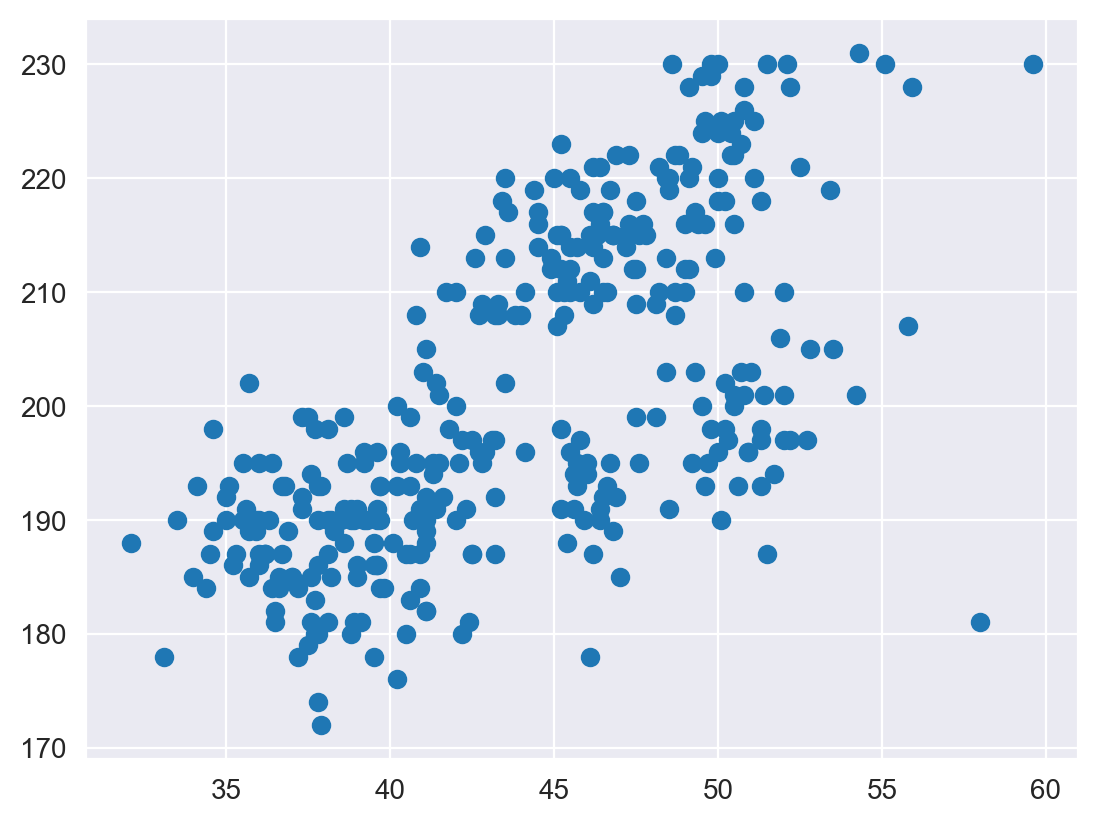

In [80]:
plt.scatter(penguins.bill_length_mm, penguins.flipper_length_mm) ;  # semi colon makes last value None

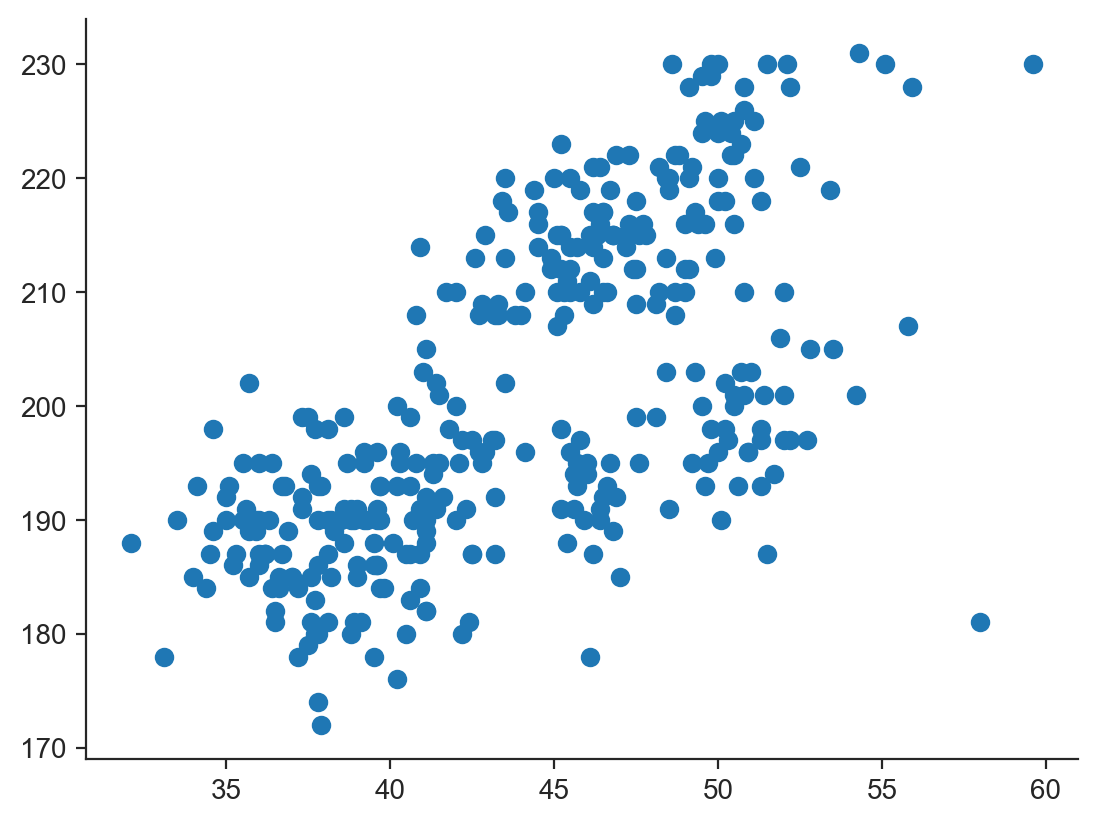

In [81]:
sns.set_style("ticks")
# sns.set_style("darkgrid")
# sns.set_style("whitegrid")
# sns.set_style("white")
# sns.set_style("dark")

plt.scatter(penguins.bill_length_mm, penguins.flipper_length_mm)
sns.despine()

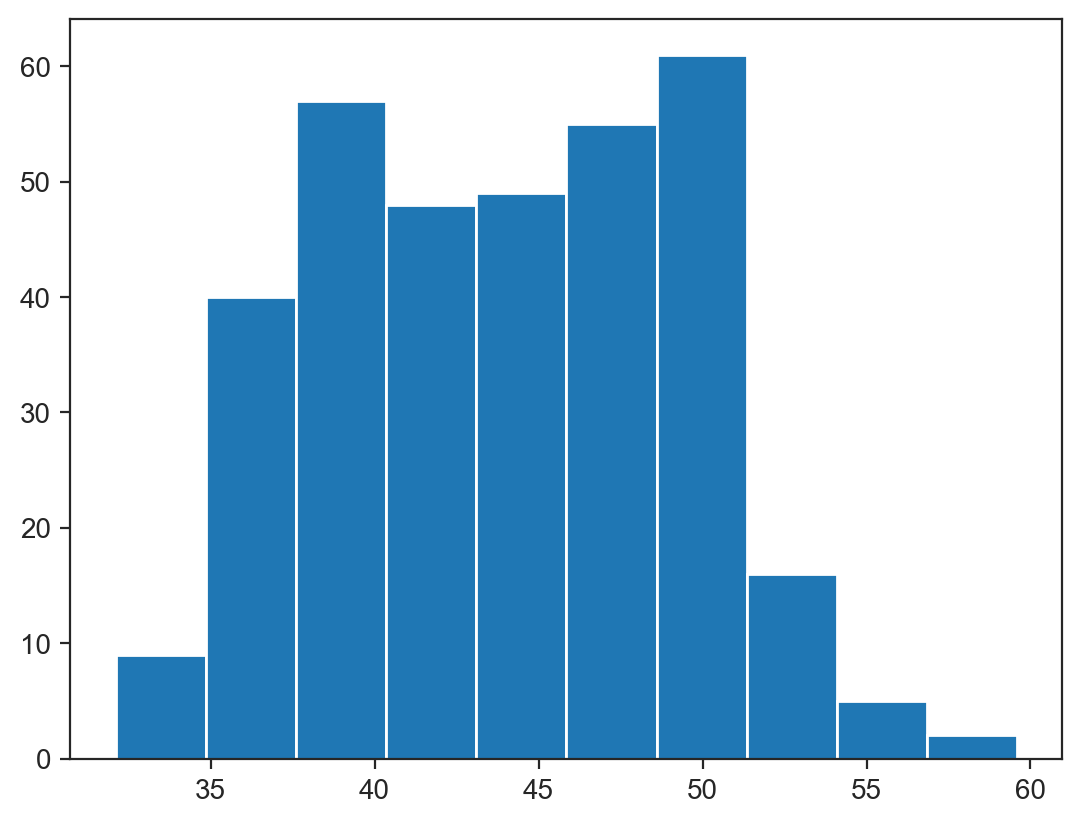

In [82]:
plt.hist(penguins.bill_length_mm) ;

# Better plotting with seaborn (on top of matplotlib)

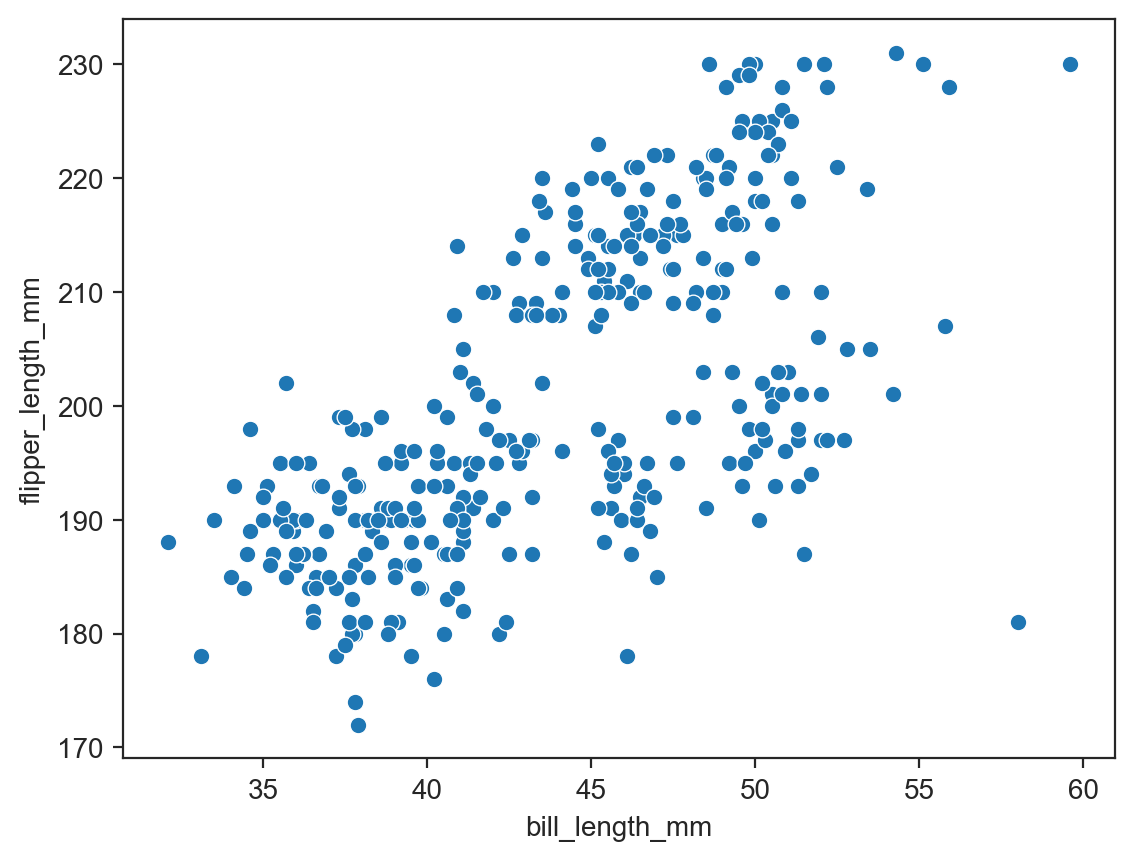

In [83]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="flipper_length_mm") ;

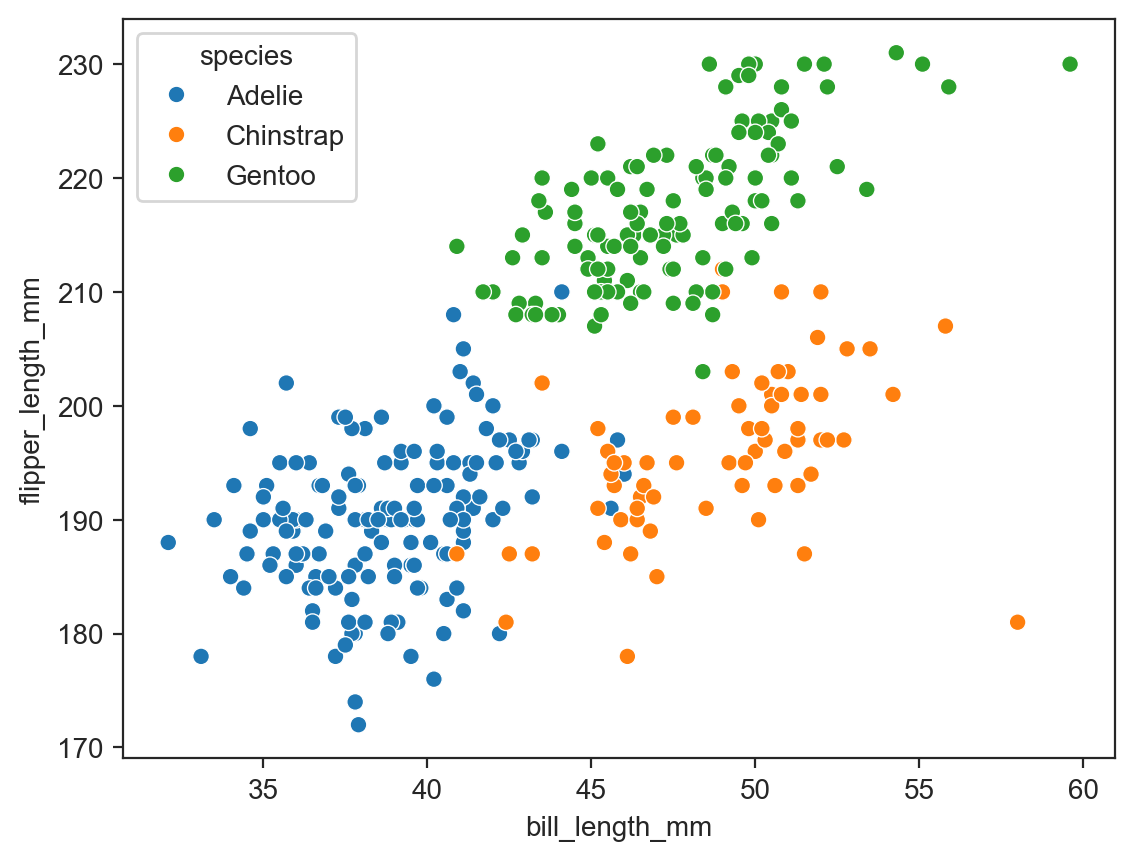

In [84]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="flipper_length_mm", hue="species") ;

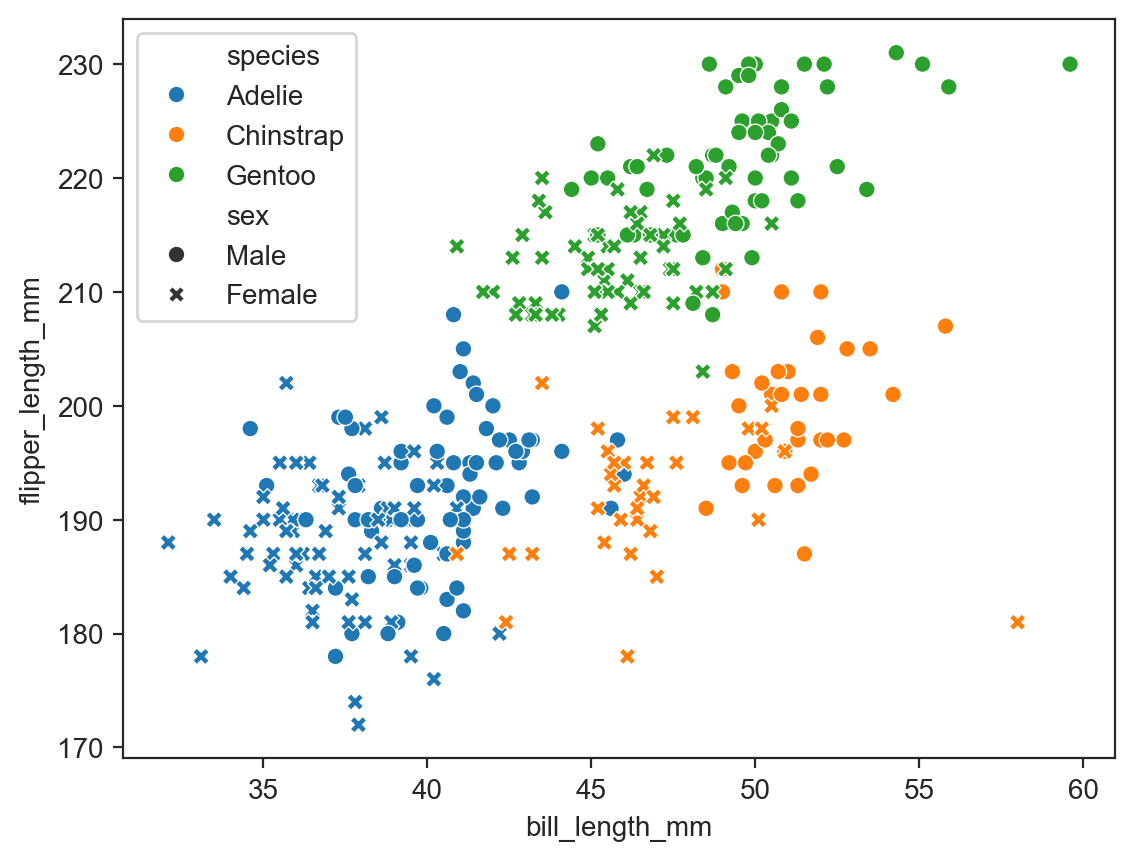

In [85]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="flipper_length_mm", hue="species", style="sex") ;

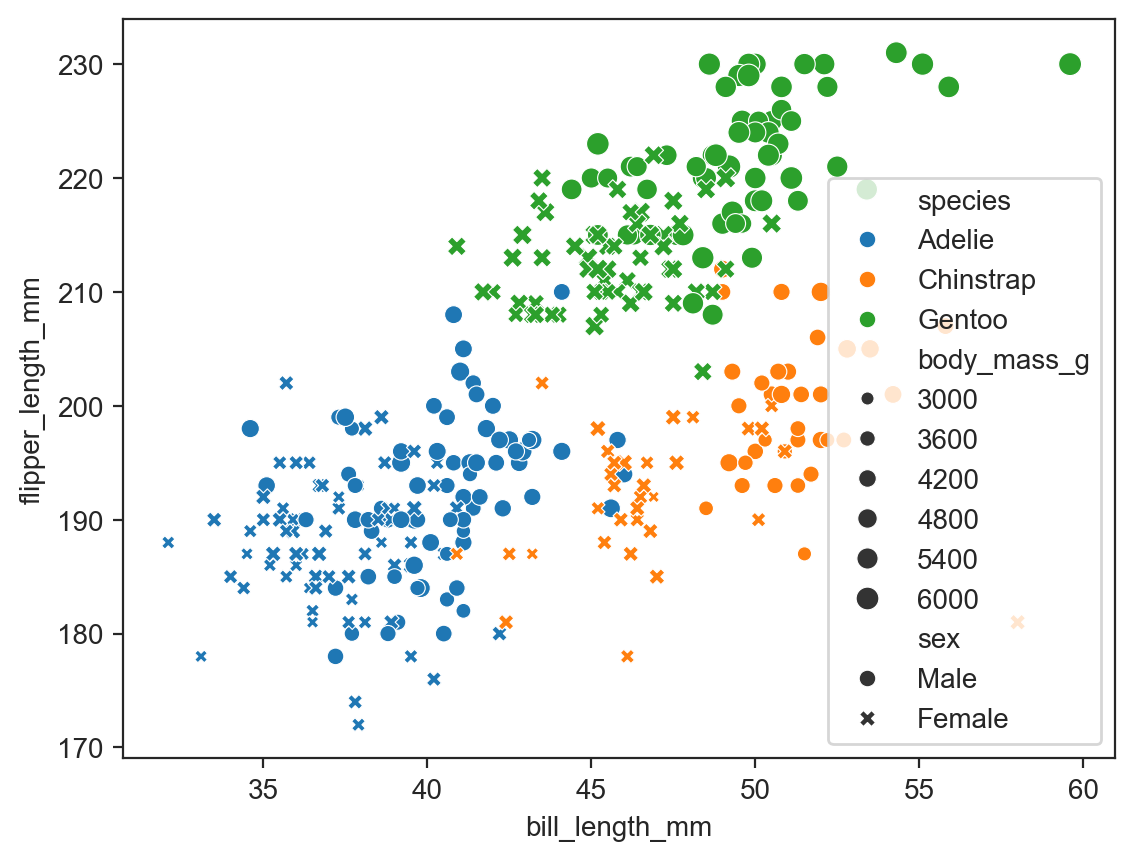

In [86]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="flipper_length_mm", hue="species", 
                style="sex", size="body_mass_g") ;

In [87]:
def legend_outside():
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)

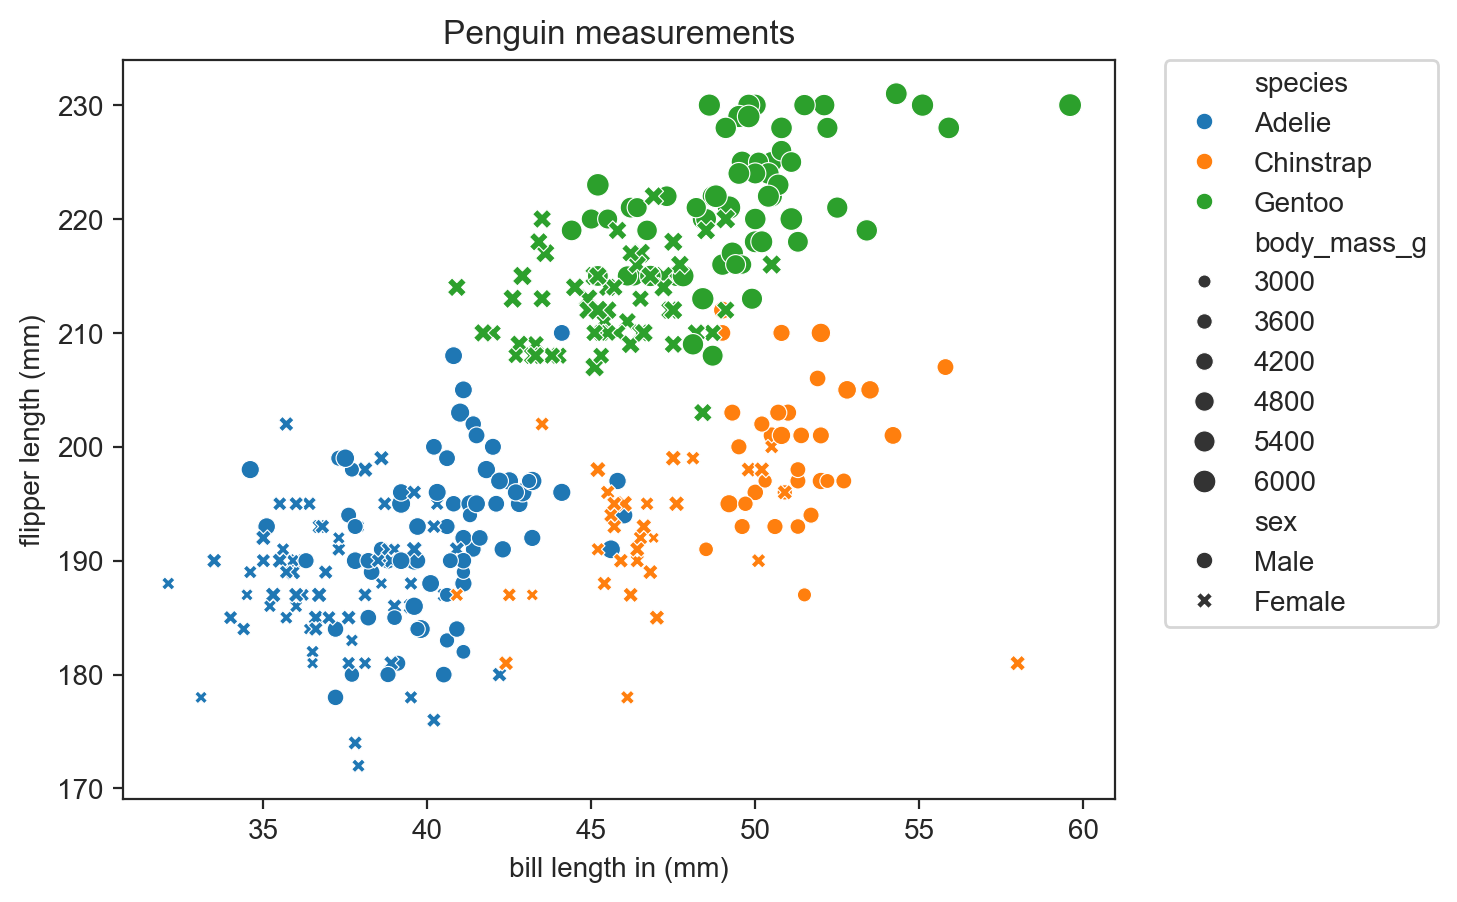

In [88]:
sns.scatterplot(data=penguins, x="bill_length_mm", y="flipper_length_mm", hue="species", style="sex", size="body_mass_g") ;

legend_outside()

plt.title("Penguin measurements")
plt.ylabel("flipper length (mm)")
plt.xlabel("bill length in (mm)") ;

# Wide or long data

Wide format data:

In [89]:
penguins[['bill_length_mm', 'bill_depth_mm']]

,bill_length_mm,bill_depth_mm
0,39.1,18.7
1,39.5,17.4
2,40.3,18.0
3,NaN,NaN
4,36.7,19.3
...,...,...
339,NaN,NaN
340,46.8,14.3
341,50.4,15.7
342,45.2,14.8


Long format data:

In [90]:
long_df = penguins.melt(value_vars=['bill_length_mm', 'bill_depth_mm'])
long_df

,variable,value
0,bill_length_mm,39.1
1,bill_length_mm,39.5
2,bill_length_mm,40.3
3,bill_length_mm,NaN
4,bill_length_mm,36.7
...,...,...
683,bill_depth_mm,NaN
684,bill_depth_mm,14.3
685,bill_depth_mm,15.7
686,bill_depth_mm,14.8


long format is required when you want a number of columns to appear as a "variable" in the plot. As in the example below where the color "variable" reflects whether the point is `bill_depth_mm` or `bill_length_mm`.

Retain other information for each observation:

In [127]:
long_df = penguins.melt(id_vars=['species', 'body_mass_g', 'island'], value_vars=['bill_length_mm', 'bill_depth_mm'])
long_df

,species,body_mass_g,island,variable,value
0,Adelie,3750.0,Torgersen,bill_length_mm,39.1
1,Adelie,3800.0,Torgersen,bill_length_mm,39.5
2,Adelie,3250.0,Torgersen,bill_length_mm,40.3
3,Adelie,NaN,Torgersen,bill_length_mm,NaN
4,Adelie,3450.0,Torgersen,bill_length_mm,36.7
...,...,...,...,...,...
683,Gentoo,NaN,Biscoe,bill_depth_mm,NaN
684,Gentoo,4850.0,Biscoe,bill_depth_mm,14.3
685,Gentoo,5750.0,Biscoe,bill_depth_mm,15.7
686,Gentoo,5200.0,Biscoe,bill_depth_mm,14.8


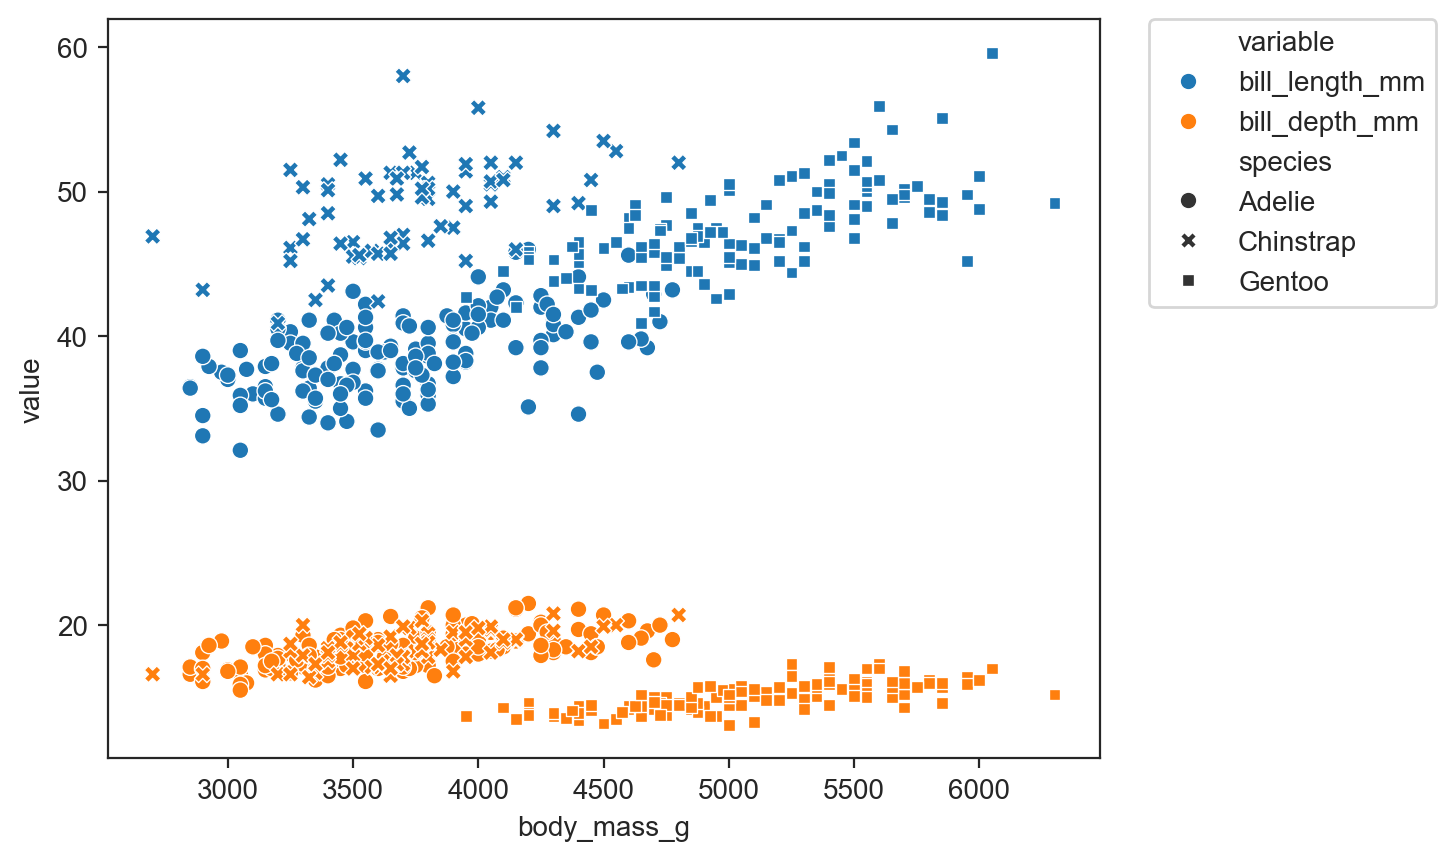

In [128]:
sns.scatterplot(data=long_df, x='body_mass_g', y='value', hue='variable', style='species')
legend_outside()

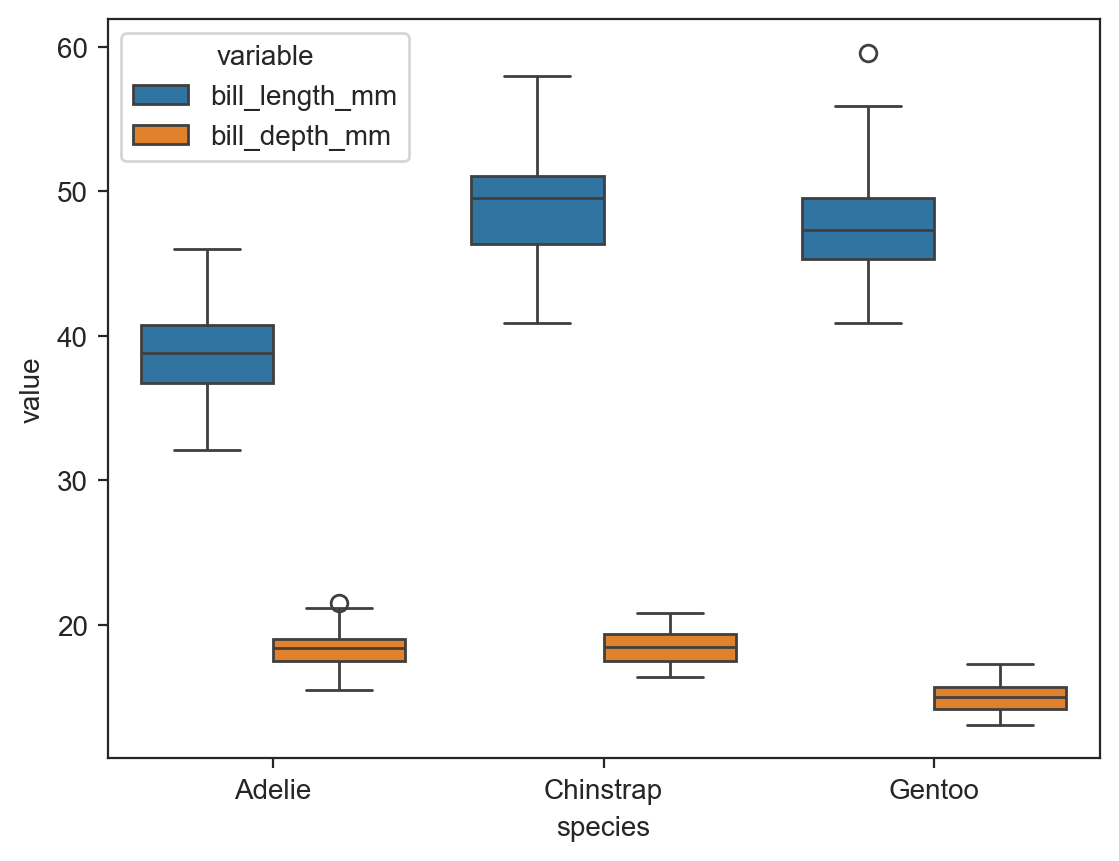

In [129]:
sns.boxplot(data=long_df, x='species', y='value', hue='variable') ;

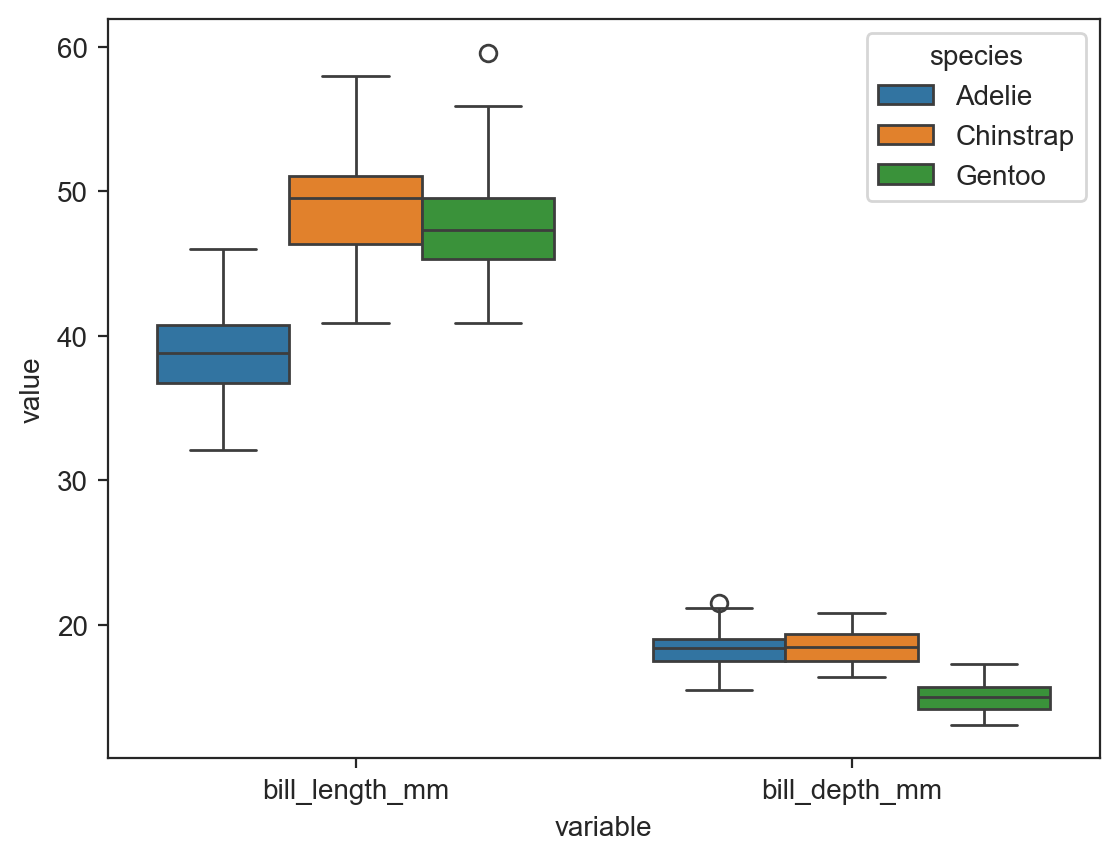

In [130]:
sns.boxplot(data=long_df, x='variable', y='value', hue='species') ;

In [ ]:
sns.boxplot(data=long_df, x='species', y='value', hue='variable') ;

# Plots with multiple facets

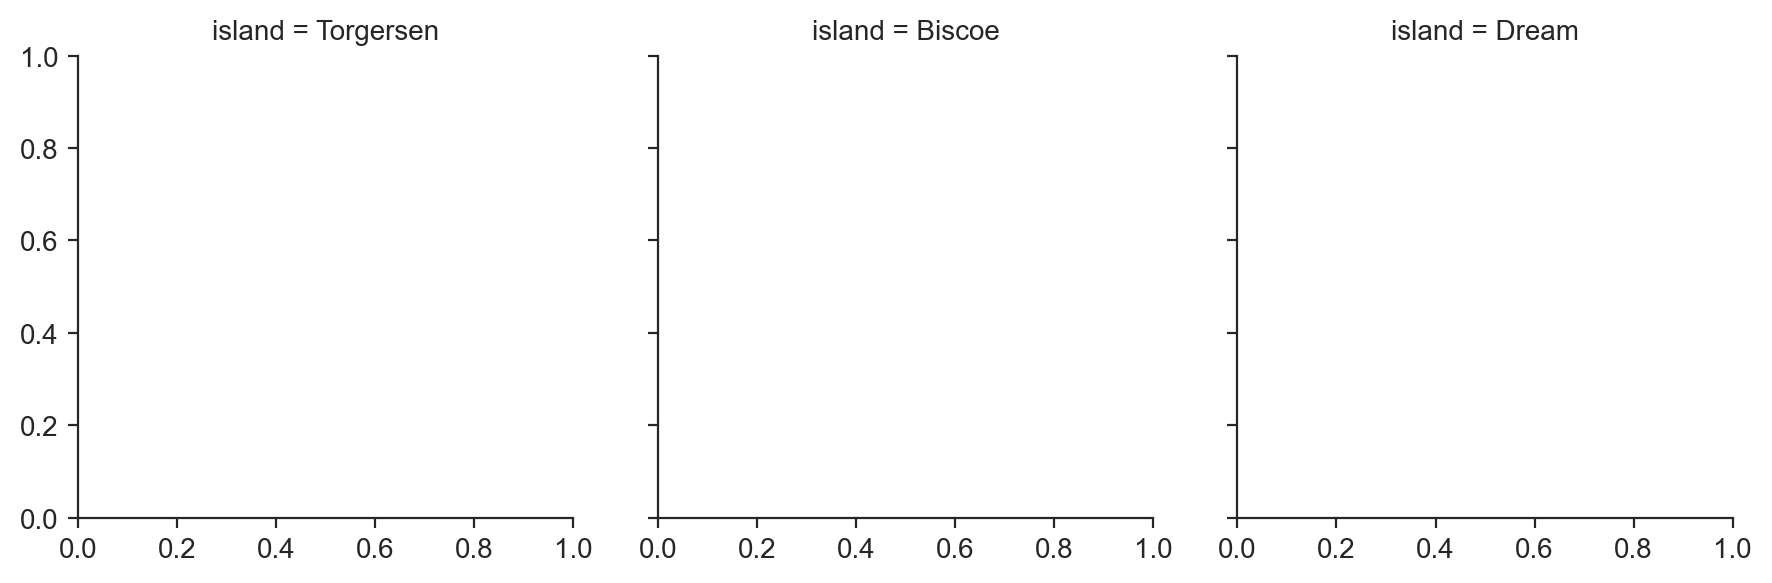

In [95]:
g = sns.FacetGrid(penguins, col="island")
g ;

Map plotting to each facet:

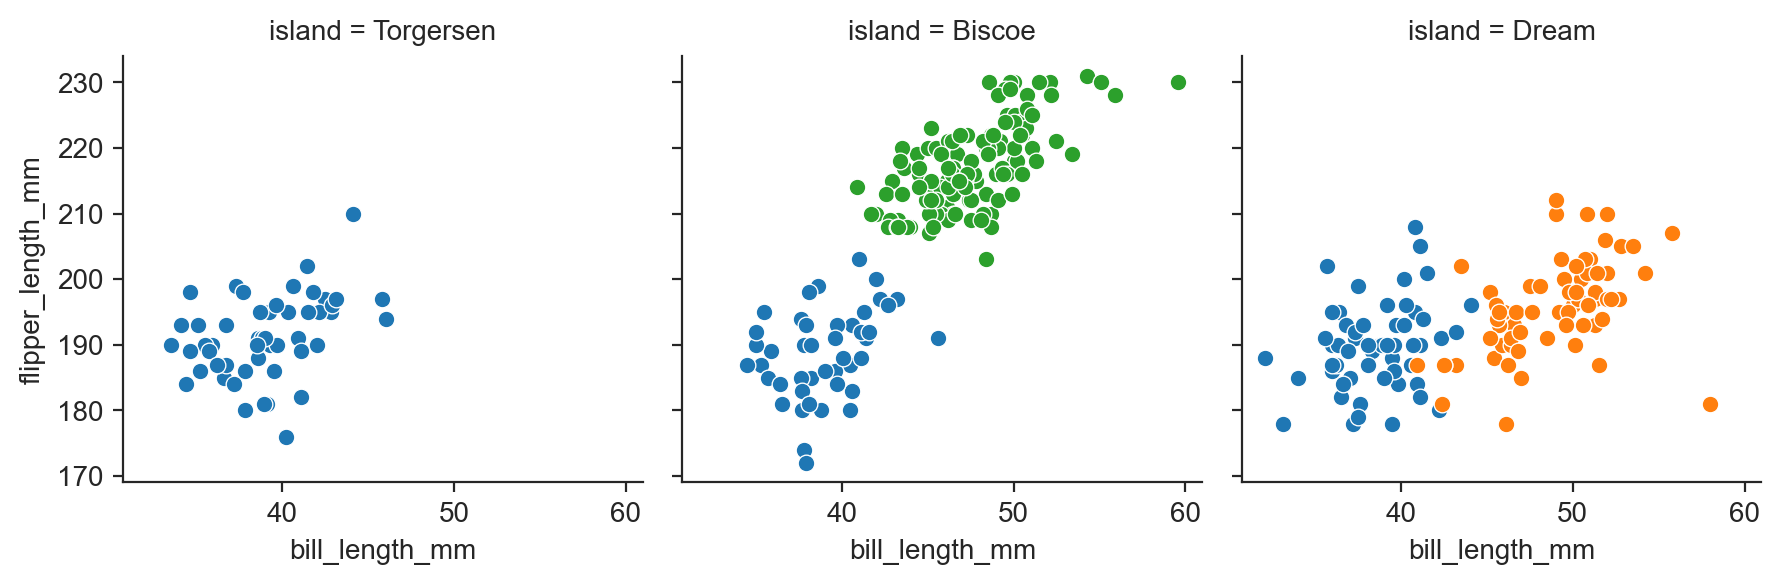

In [96]:
g = sns.FacetGrid(penguins, col="island", hue="species") ;
g.map(sns.scatterplot, "bill_length_mm", "flipper_length_mm") ;

Grid of facets representing combinations of two variables:

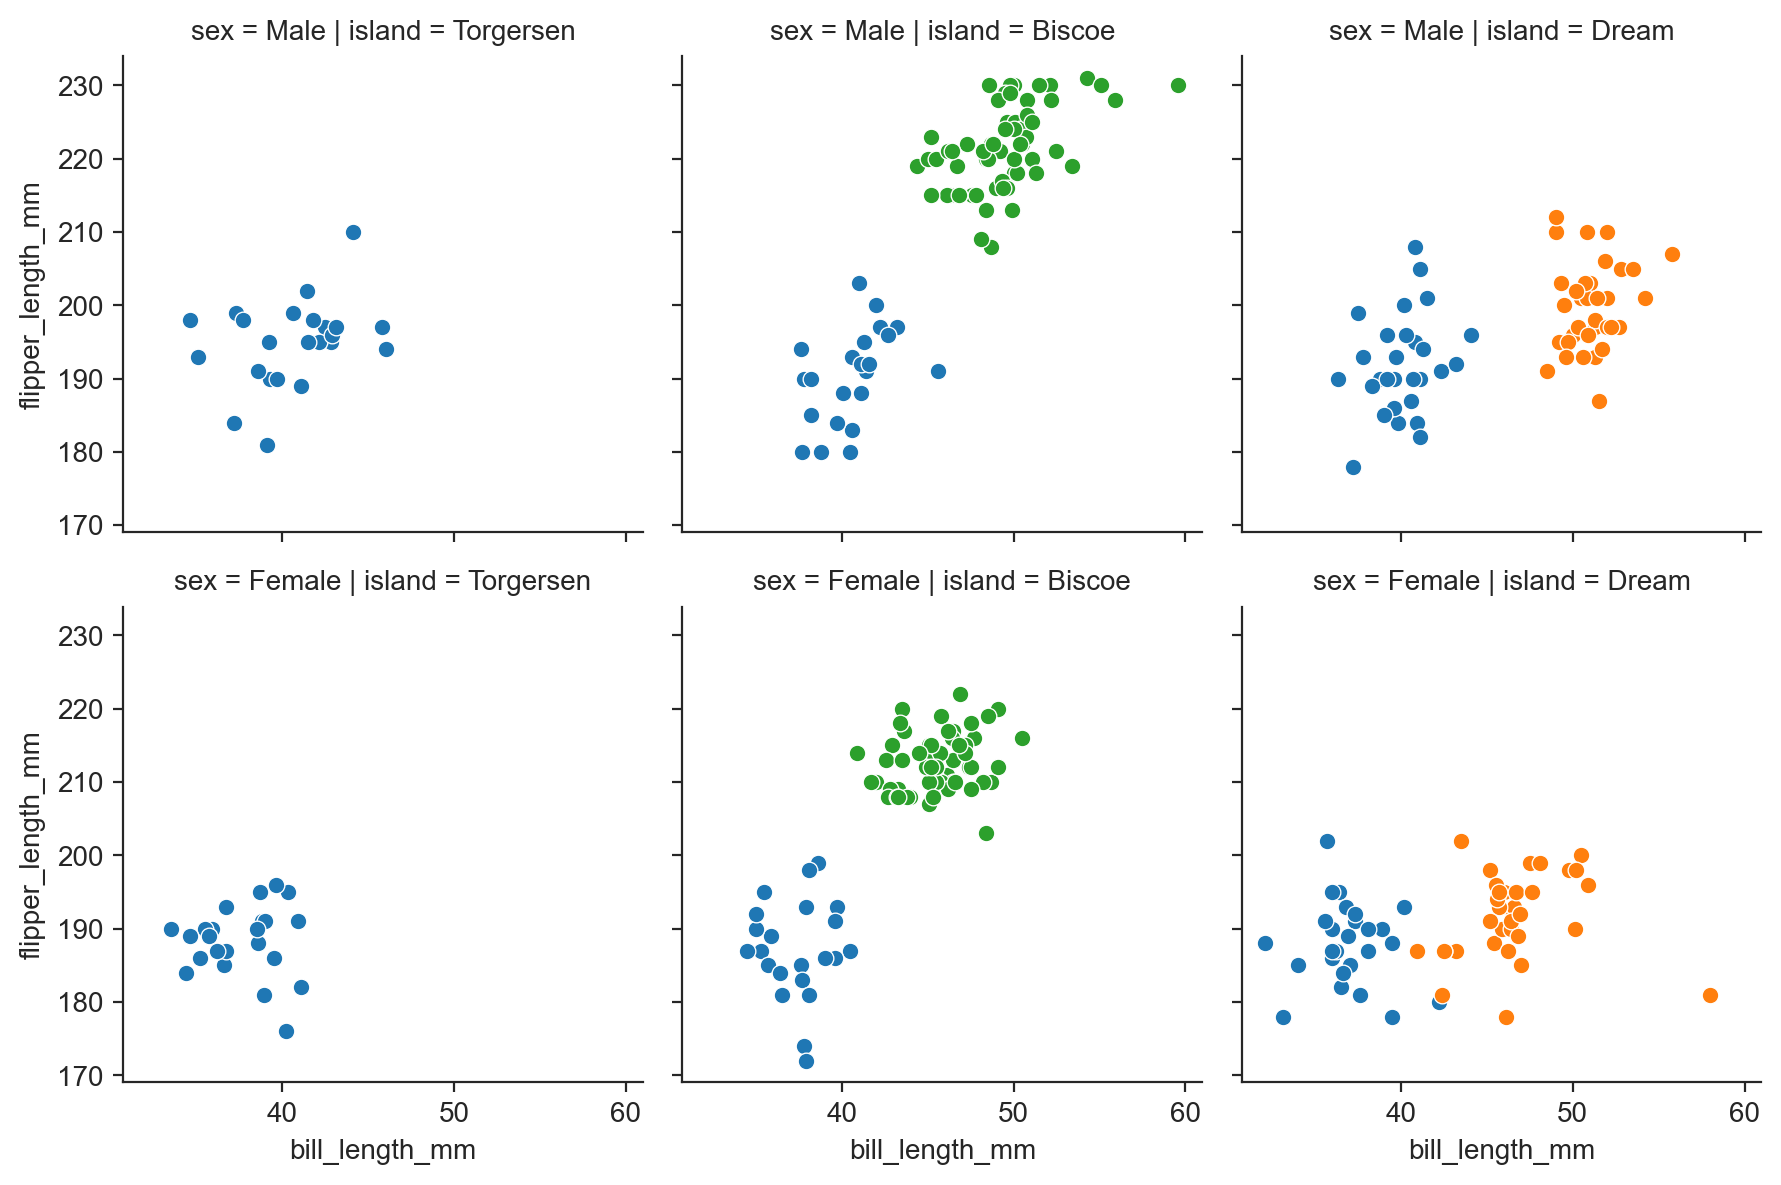

In [97]:
g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map(sns.scatterplot, "bill_length_mm", "flipper_length_mm") ;

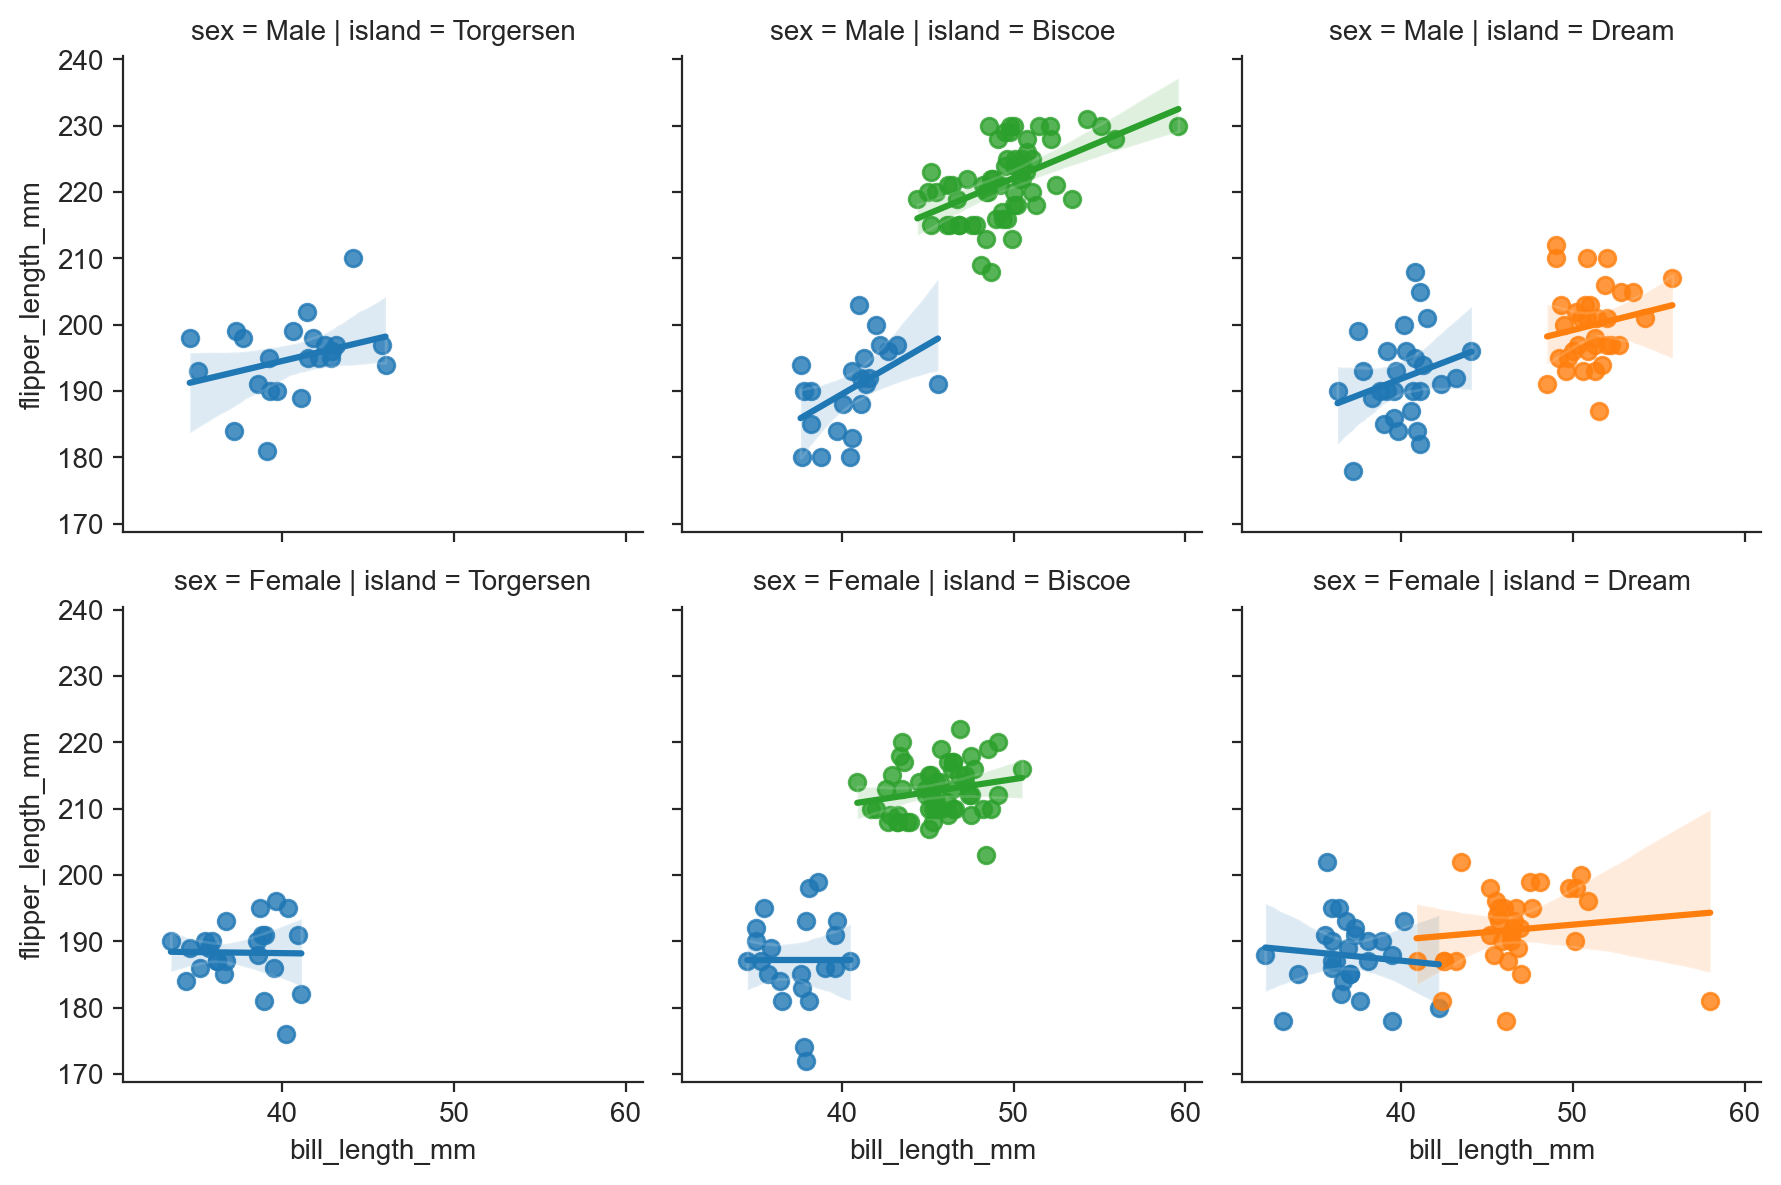

In [98]:
g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map(sns.regplot, "bill_length_mm", "flipper_length_mm") ;

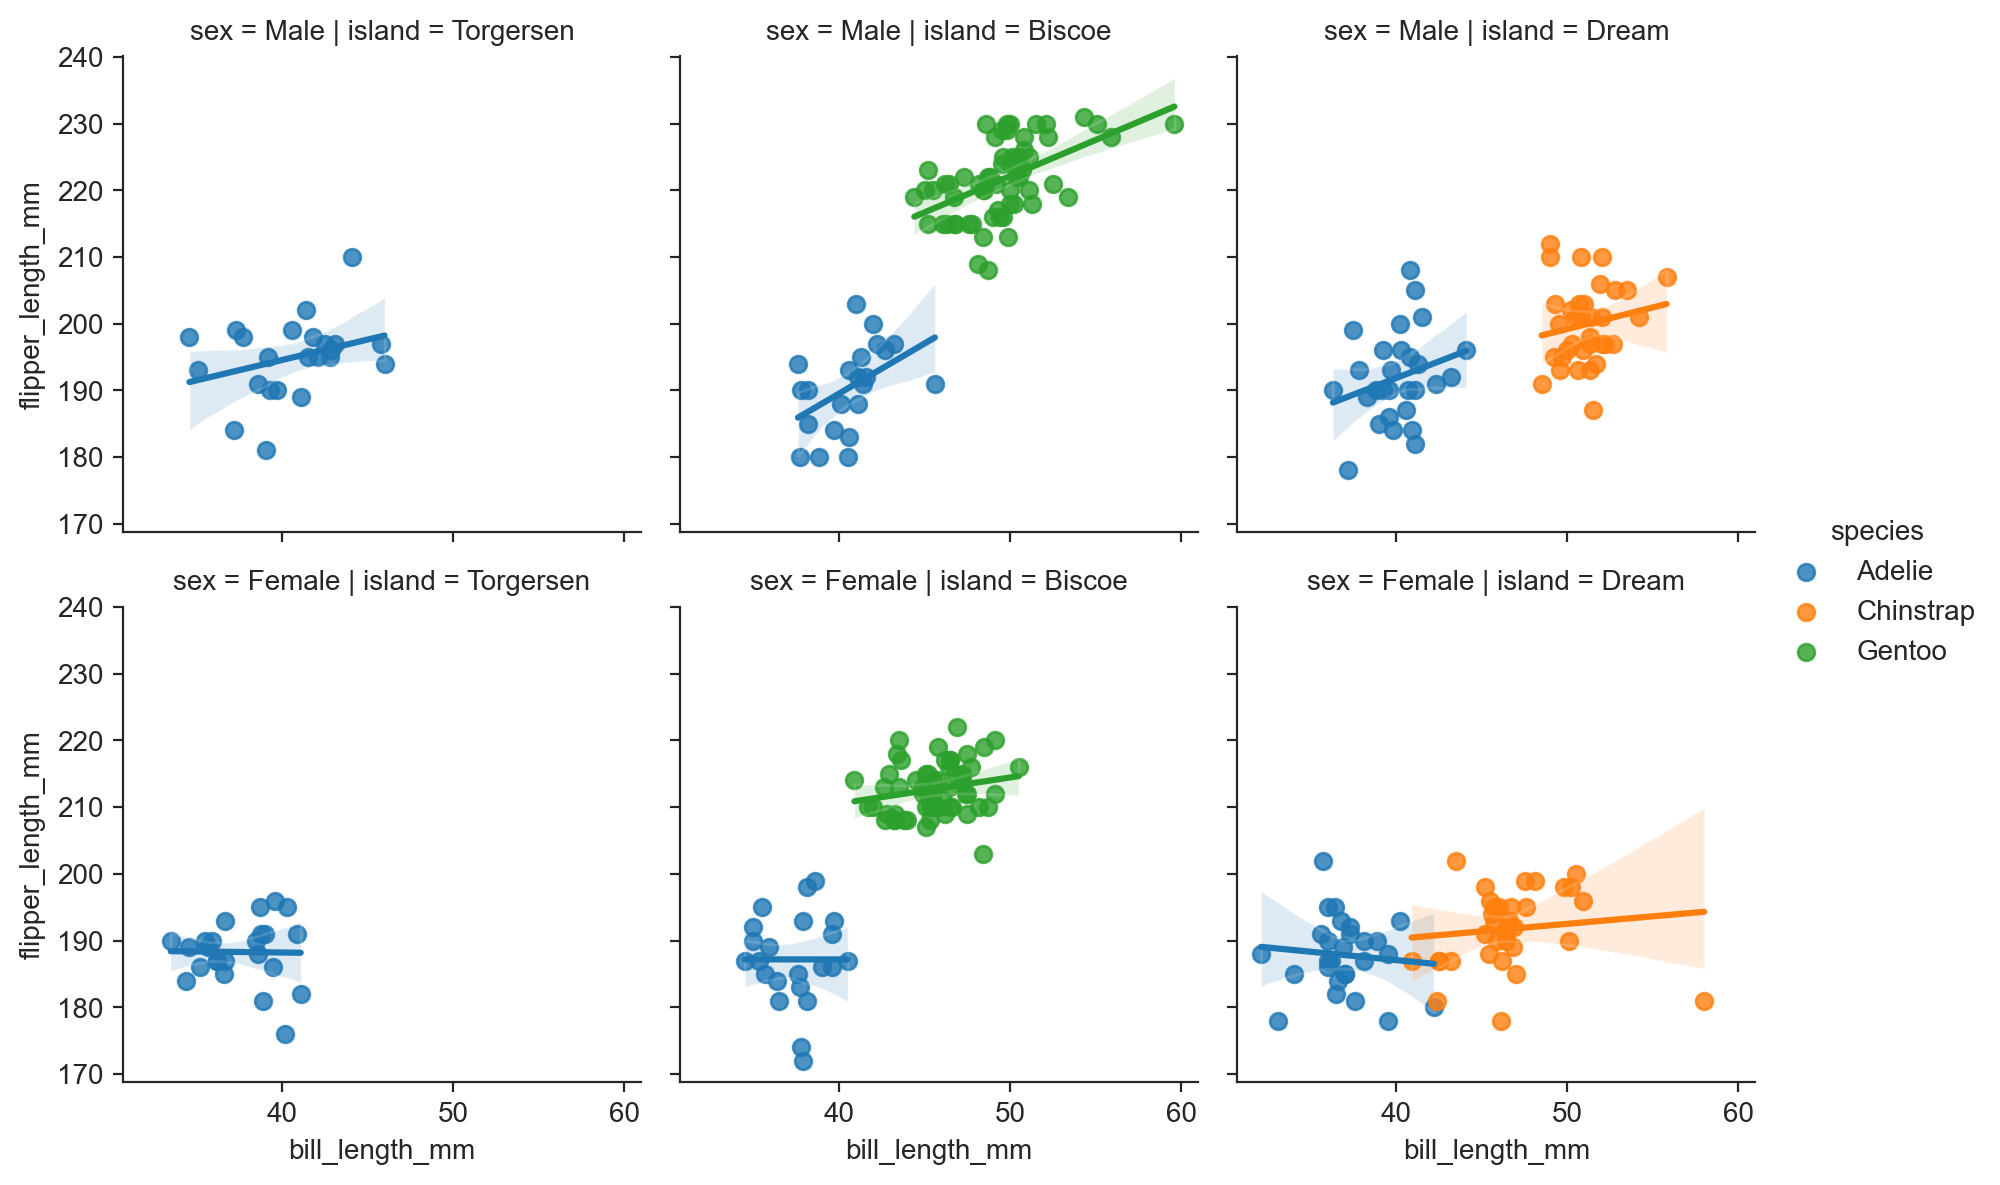

In [99]:
sns.lmplot(data=penguins, x="bill_length_mm", y="flipper_length_mm", row="sex", col="island", hue="species", height=3) ;

## FacetGrid.map vs. FacetGrid.map_dataframe

When you use `FacetGrid.map(func, "col1", "col2", ...)`, the function `func` is passed the values of the columns `"col1"` and `"col2"` (and more if needed) as parameters 1 and 2 (`args[0]`, `args[1]`, ...). In addition, the function always receives a keyword argument named `color=`.

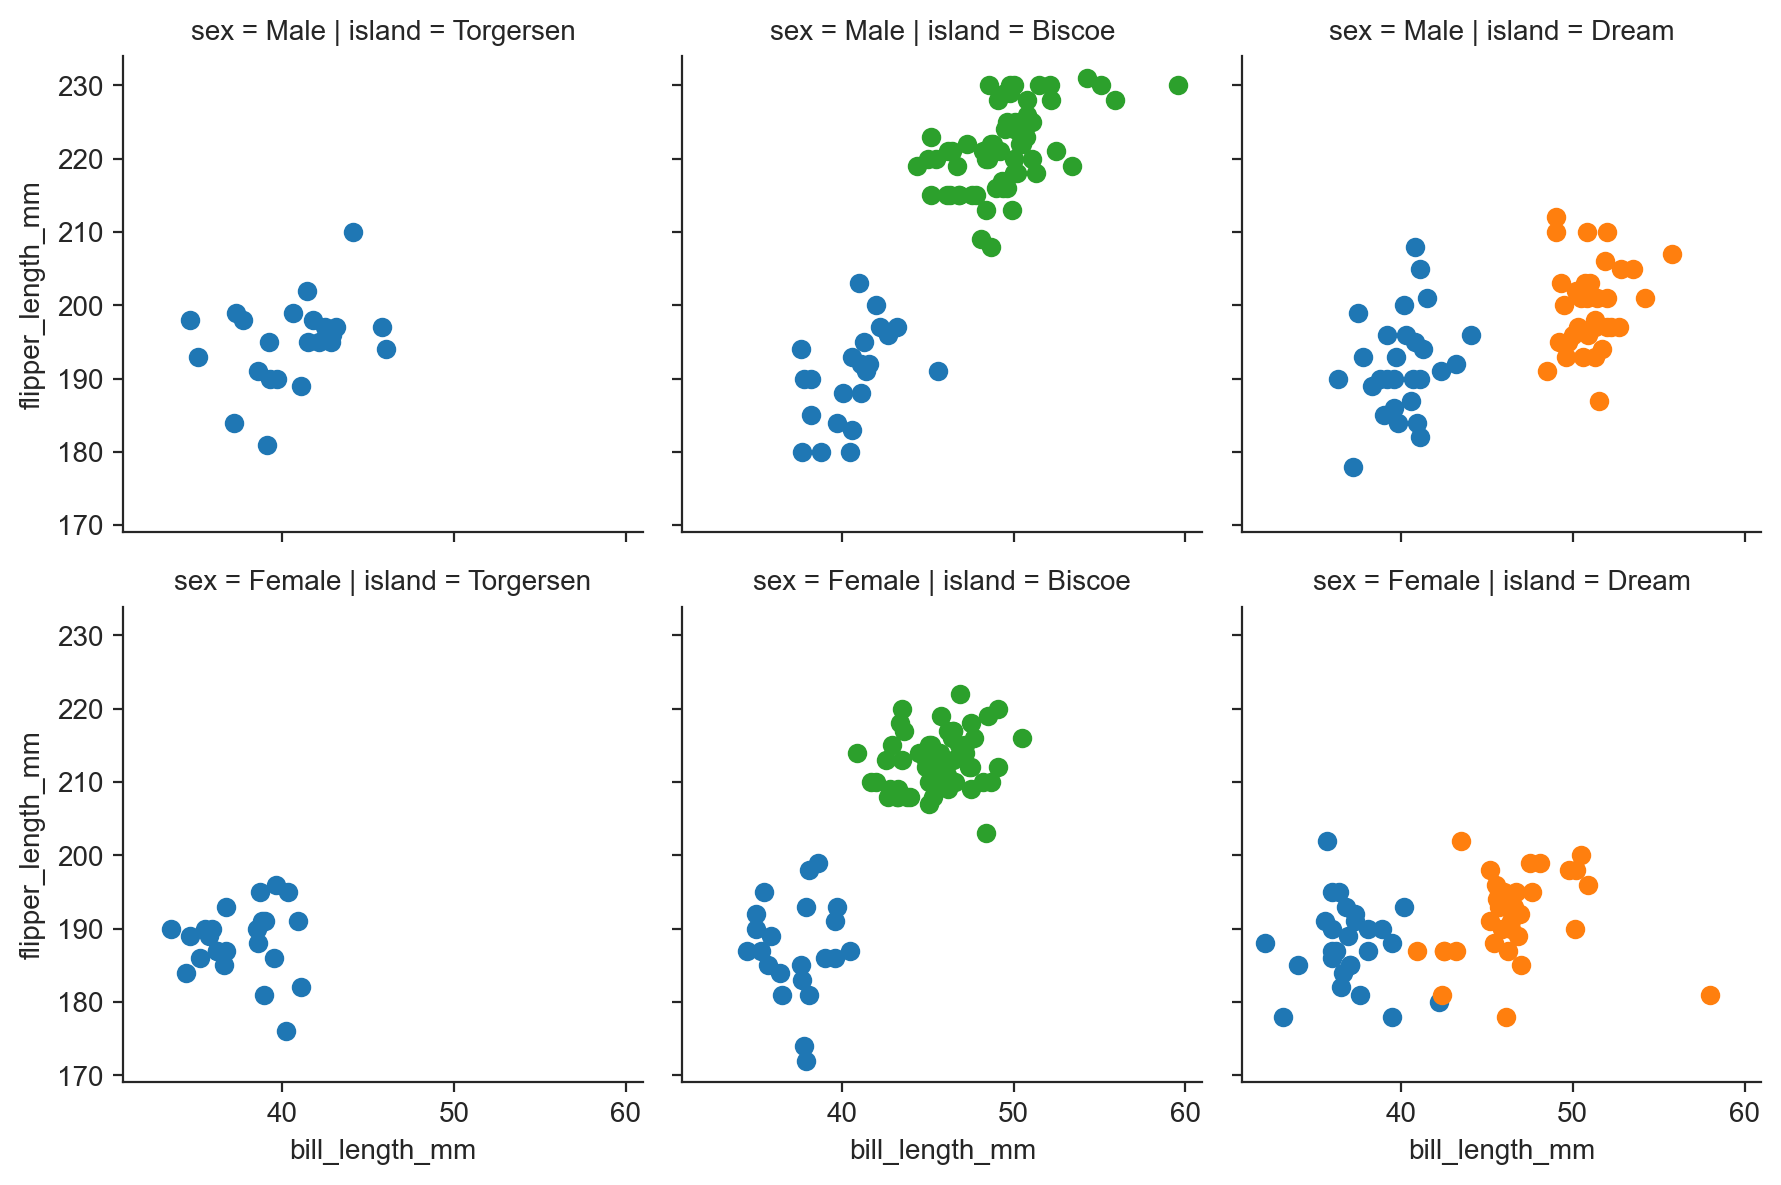

In [100]:
def scatter(*args, **kwargs):
    return plt.scatter(args[0], args[1], **kwargs)
    
g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map(scatter, "bill_length_mm", "flipper_length_mm") ;

When you use `FacetGrid.map_dataframe(func, "col1", "col2", ...)`, the function `func` is passed the names `"col1"` and `"col2"` (and more if needed) as parameters 1 and 2 (`args[0]`, `args[1]`, ...), and the filtered dataframe as keyword argument `data=`. In addition, the function always receives a keyword argument named `color=`.

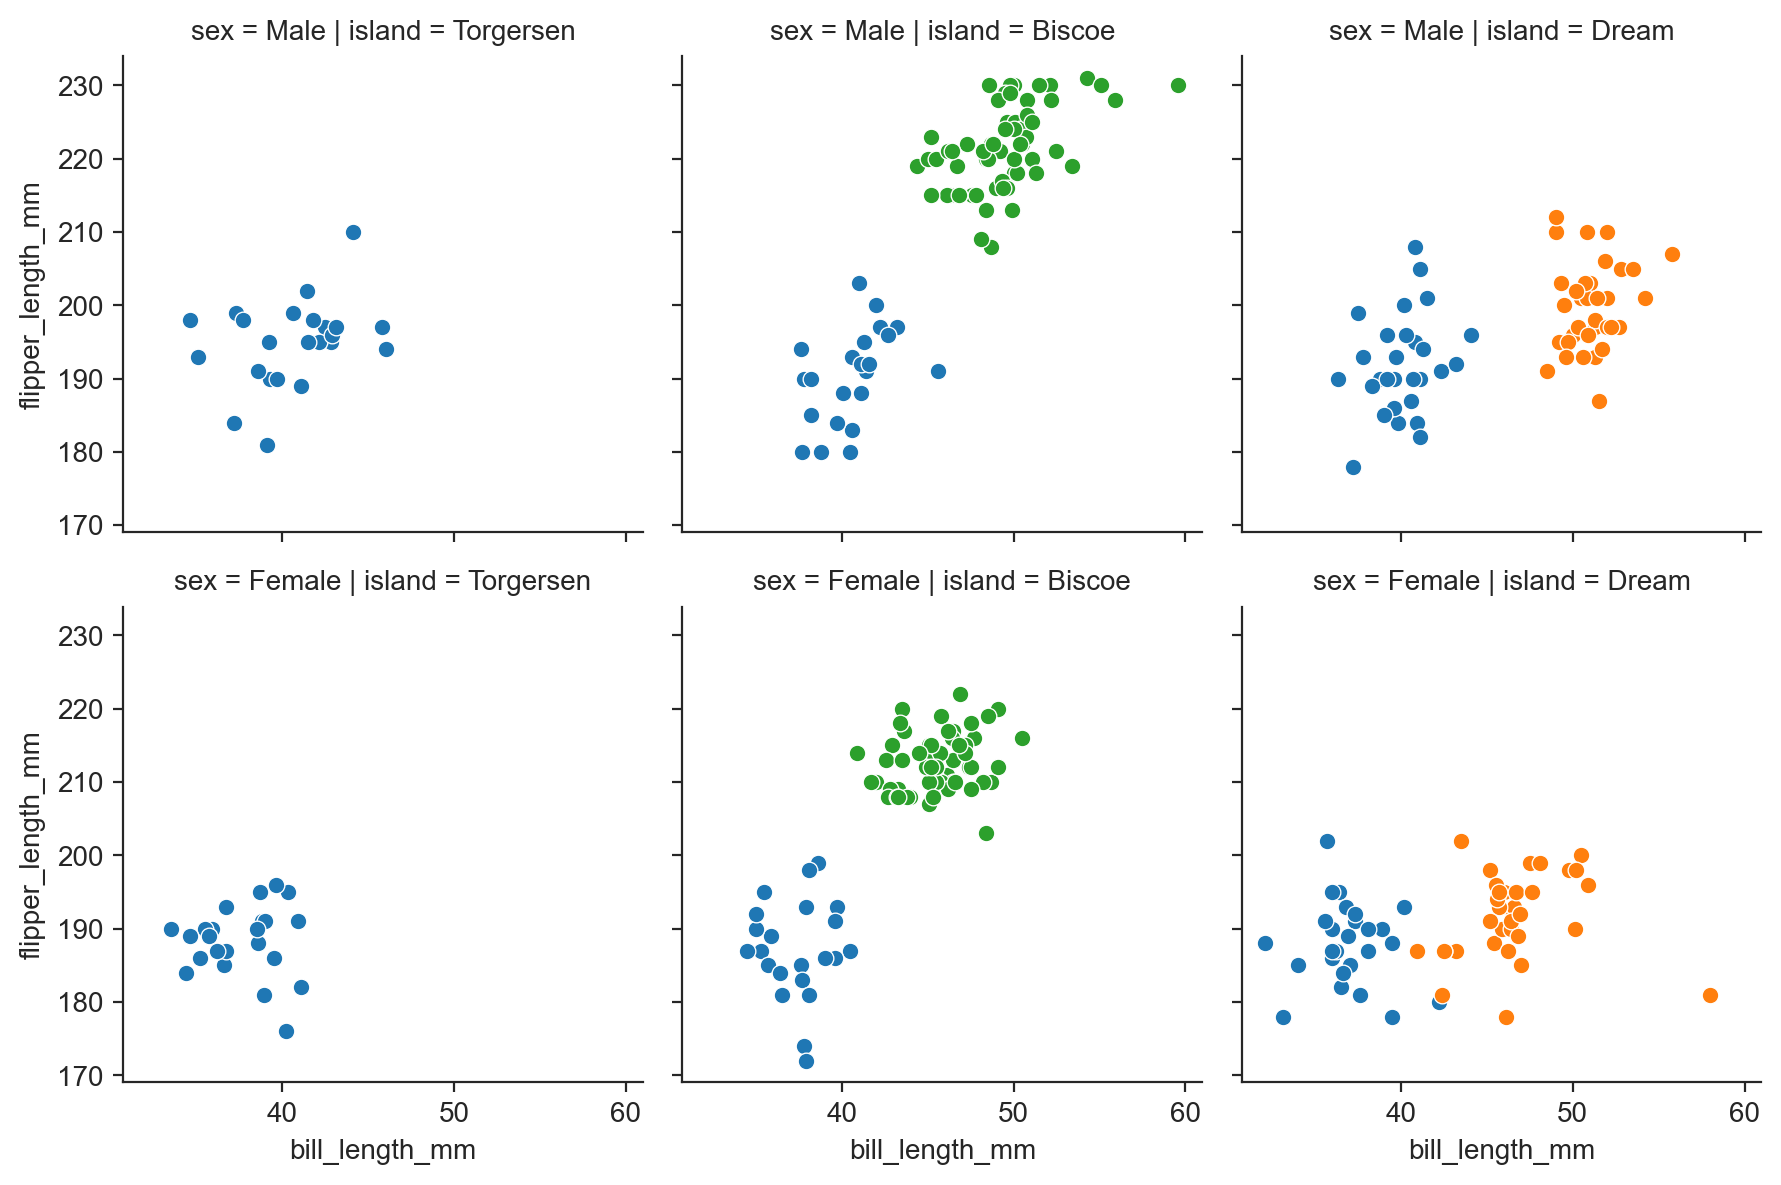

In [101]:
def scatterplot(*args, **kwargs):
    return sns.scatterplot(x=args[0], y=args[1], **kwargs)

g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map_dataframe(scatterplot, "bill_length_mm", "flipper_length_mm") ;

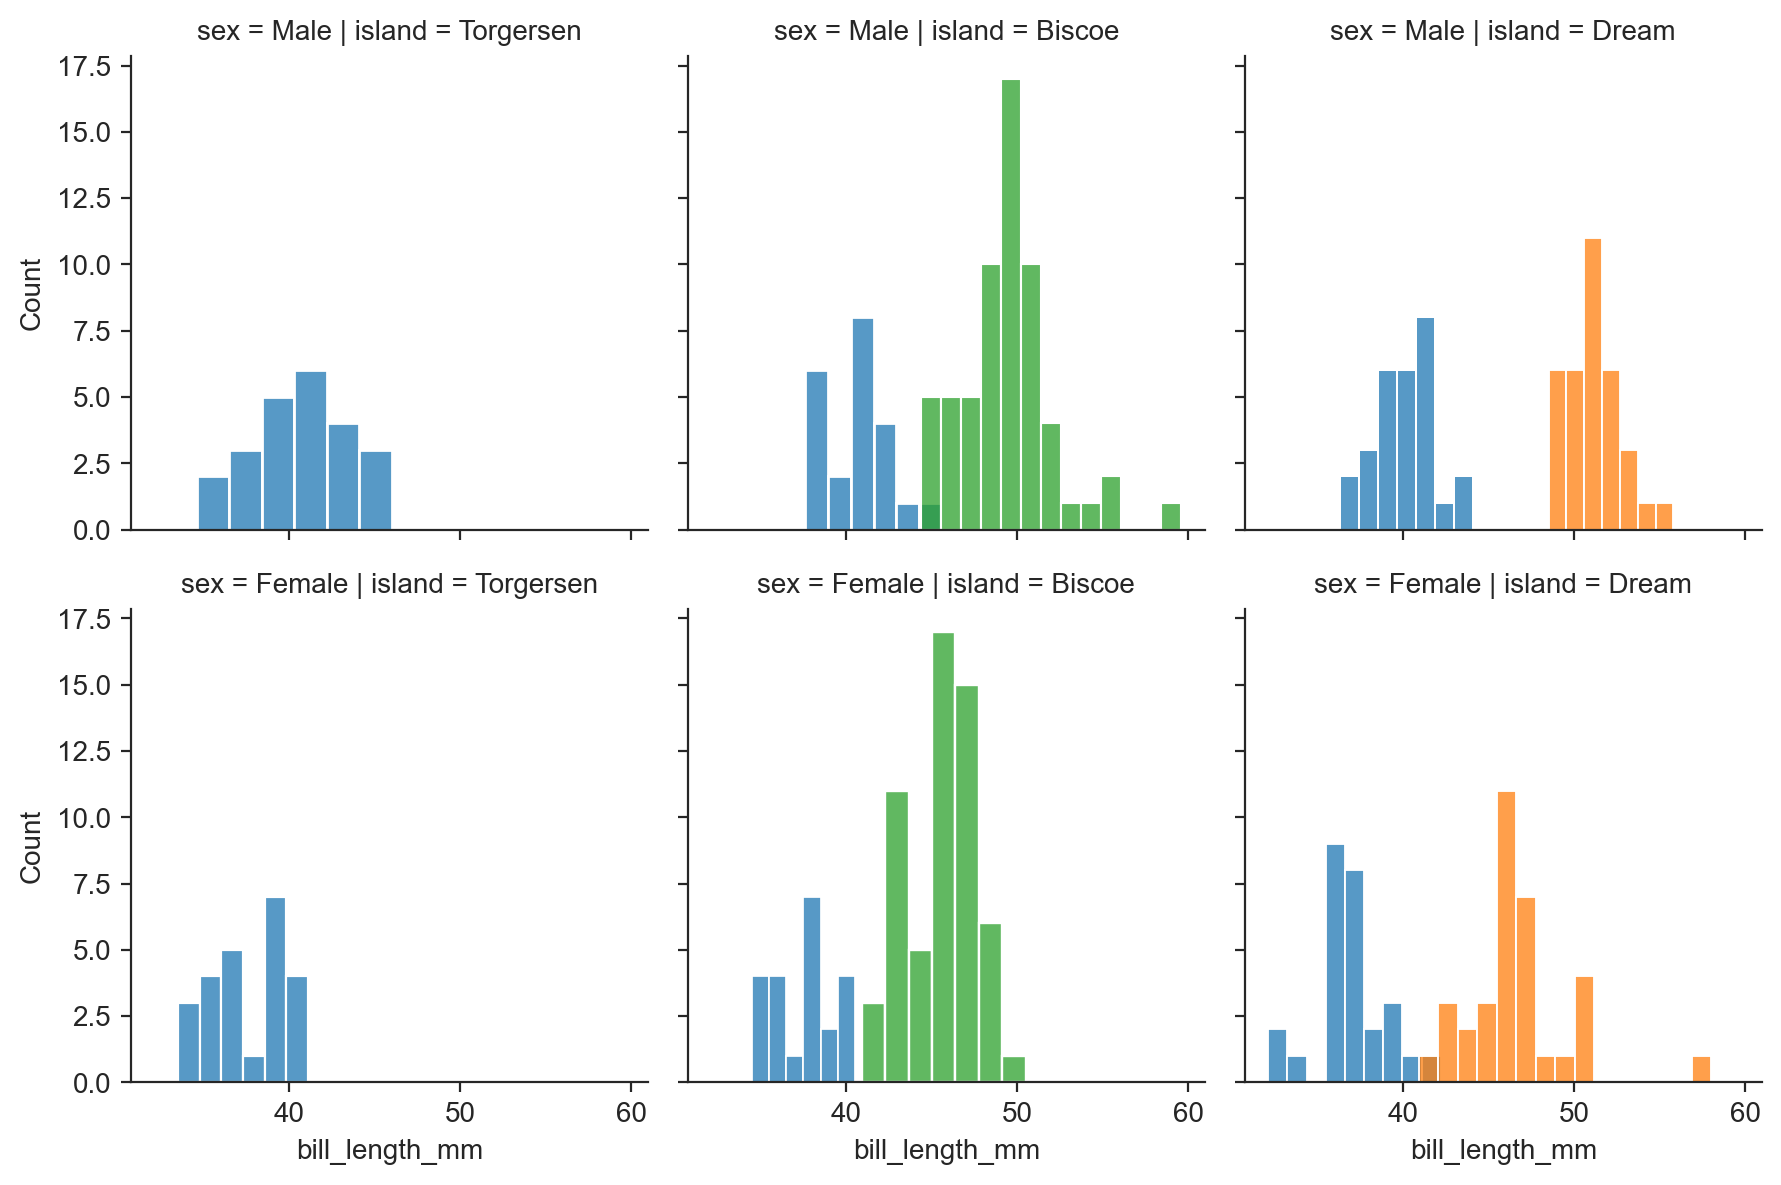

In [102]:
g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map(sns.histplot, "bill_length_mm") ;

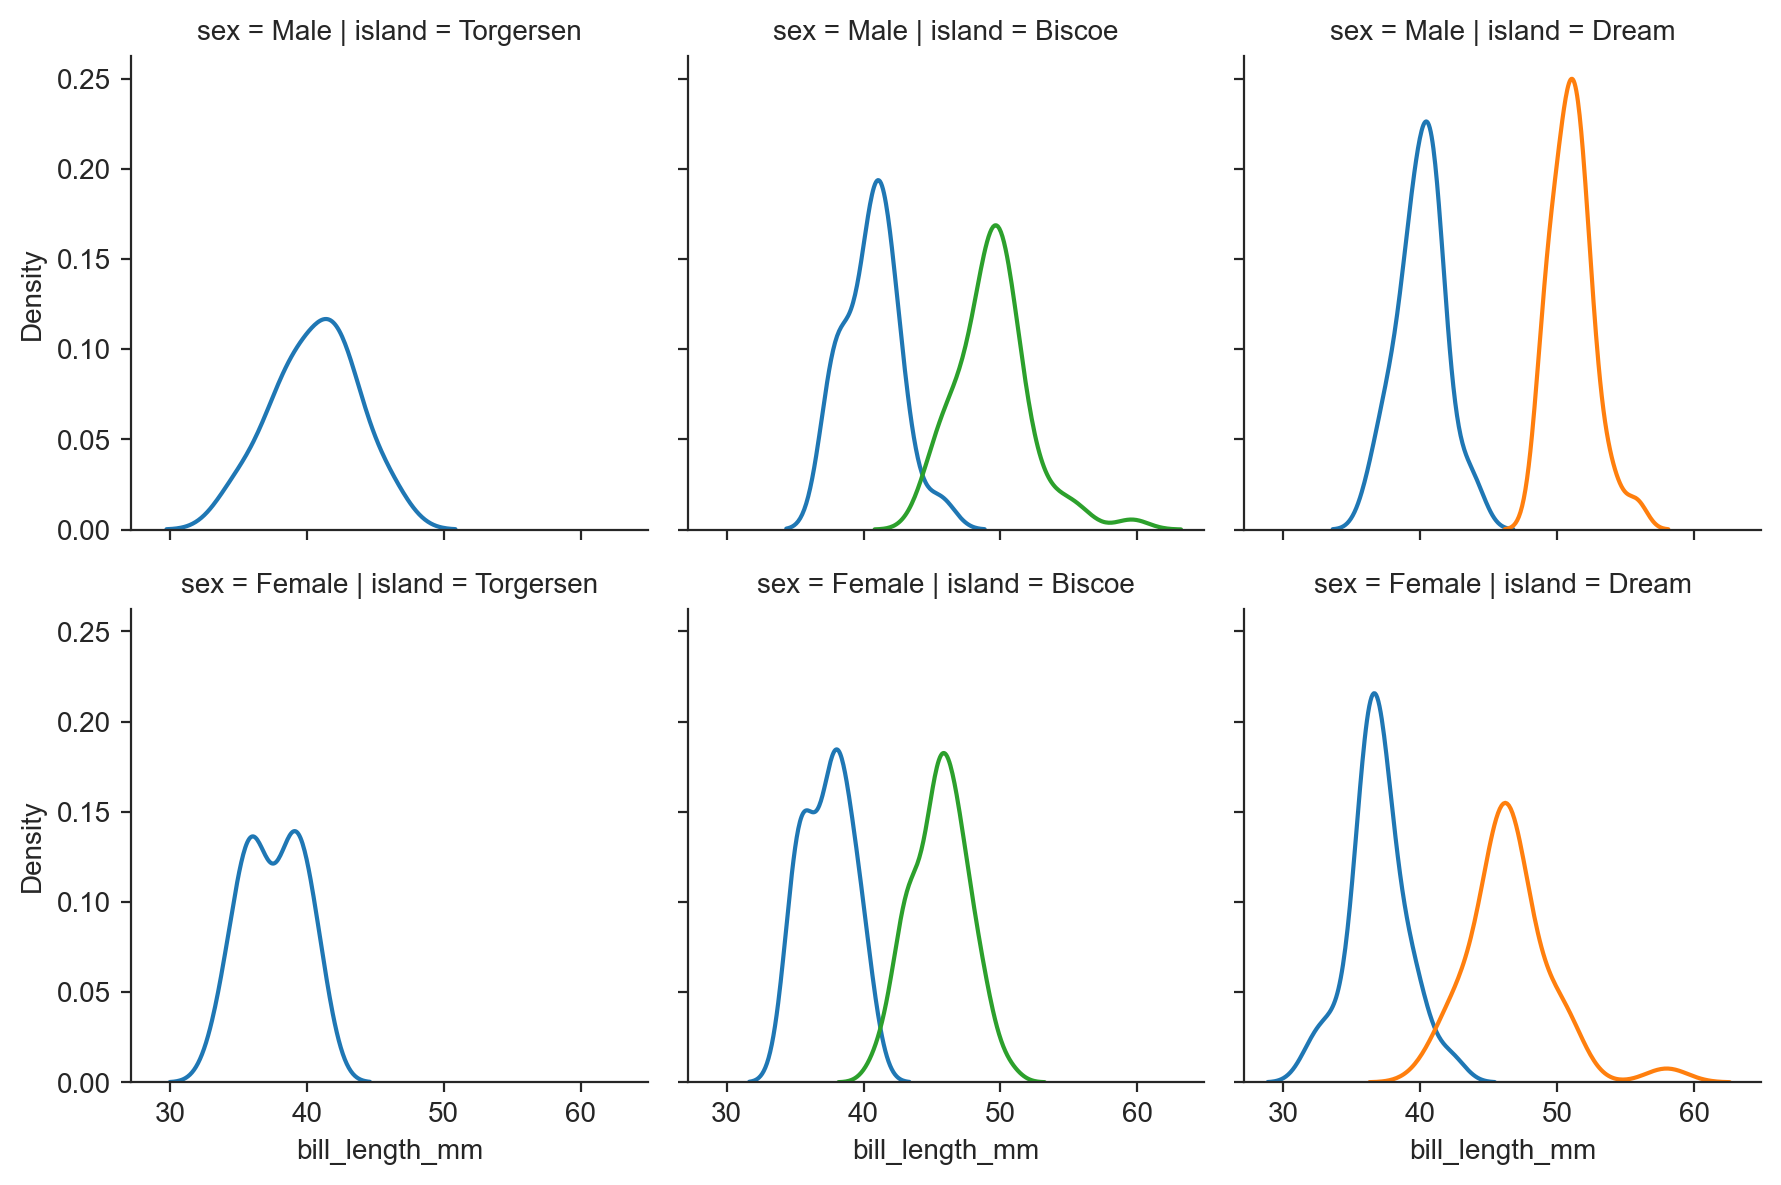

In [103]:
g = sns.FacetGrid(penguins, row="sex", col="island", hue="species") ;
g.map(sns.kdeplot, "bill_length_mm") ;

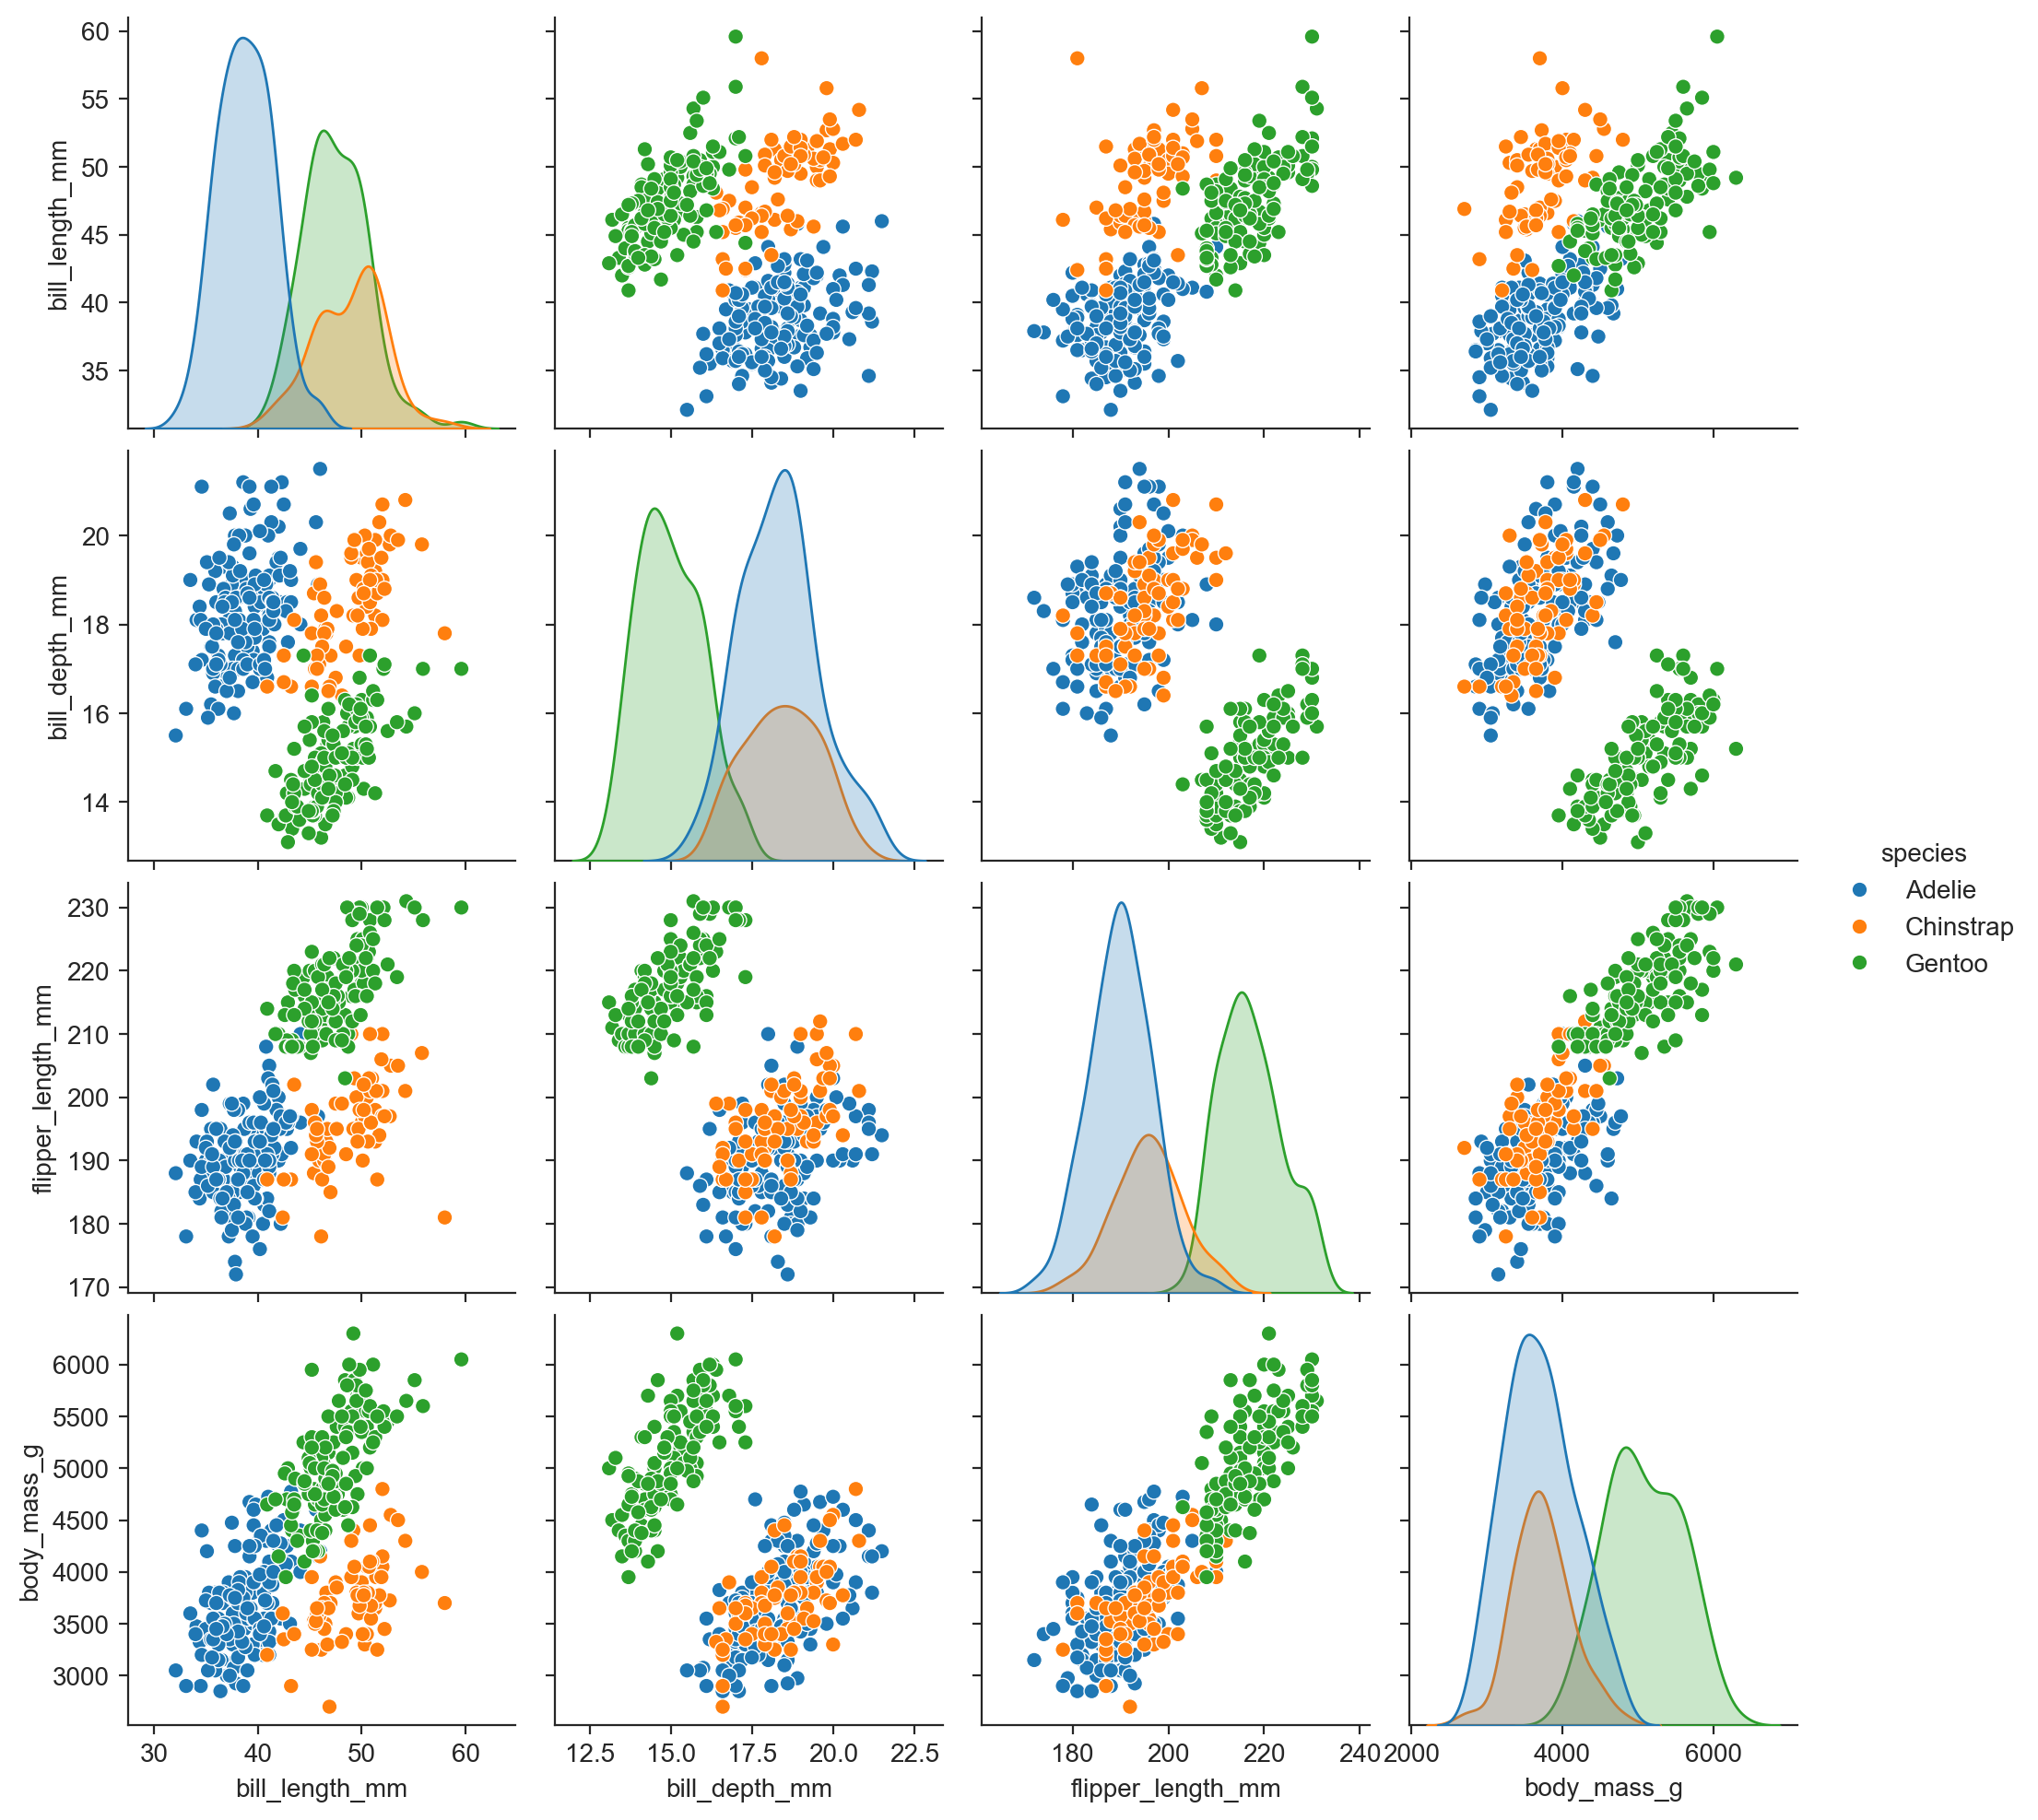

In [104]:
sns.pairplot(penguins, hue="species") ;

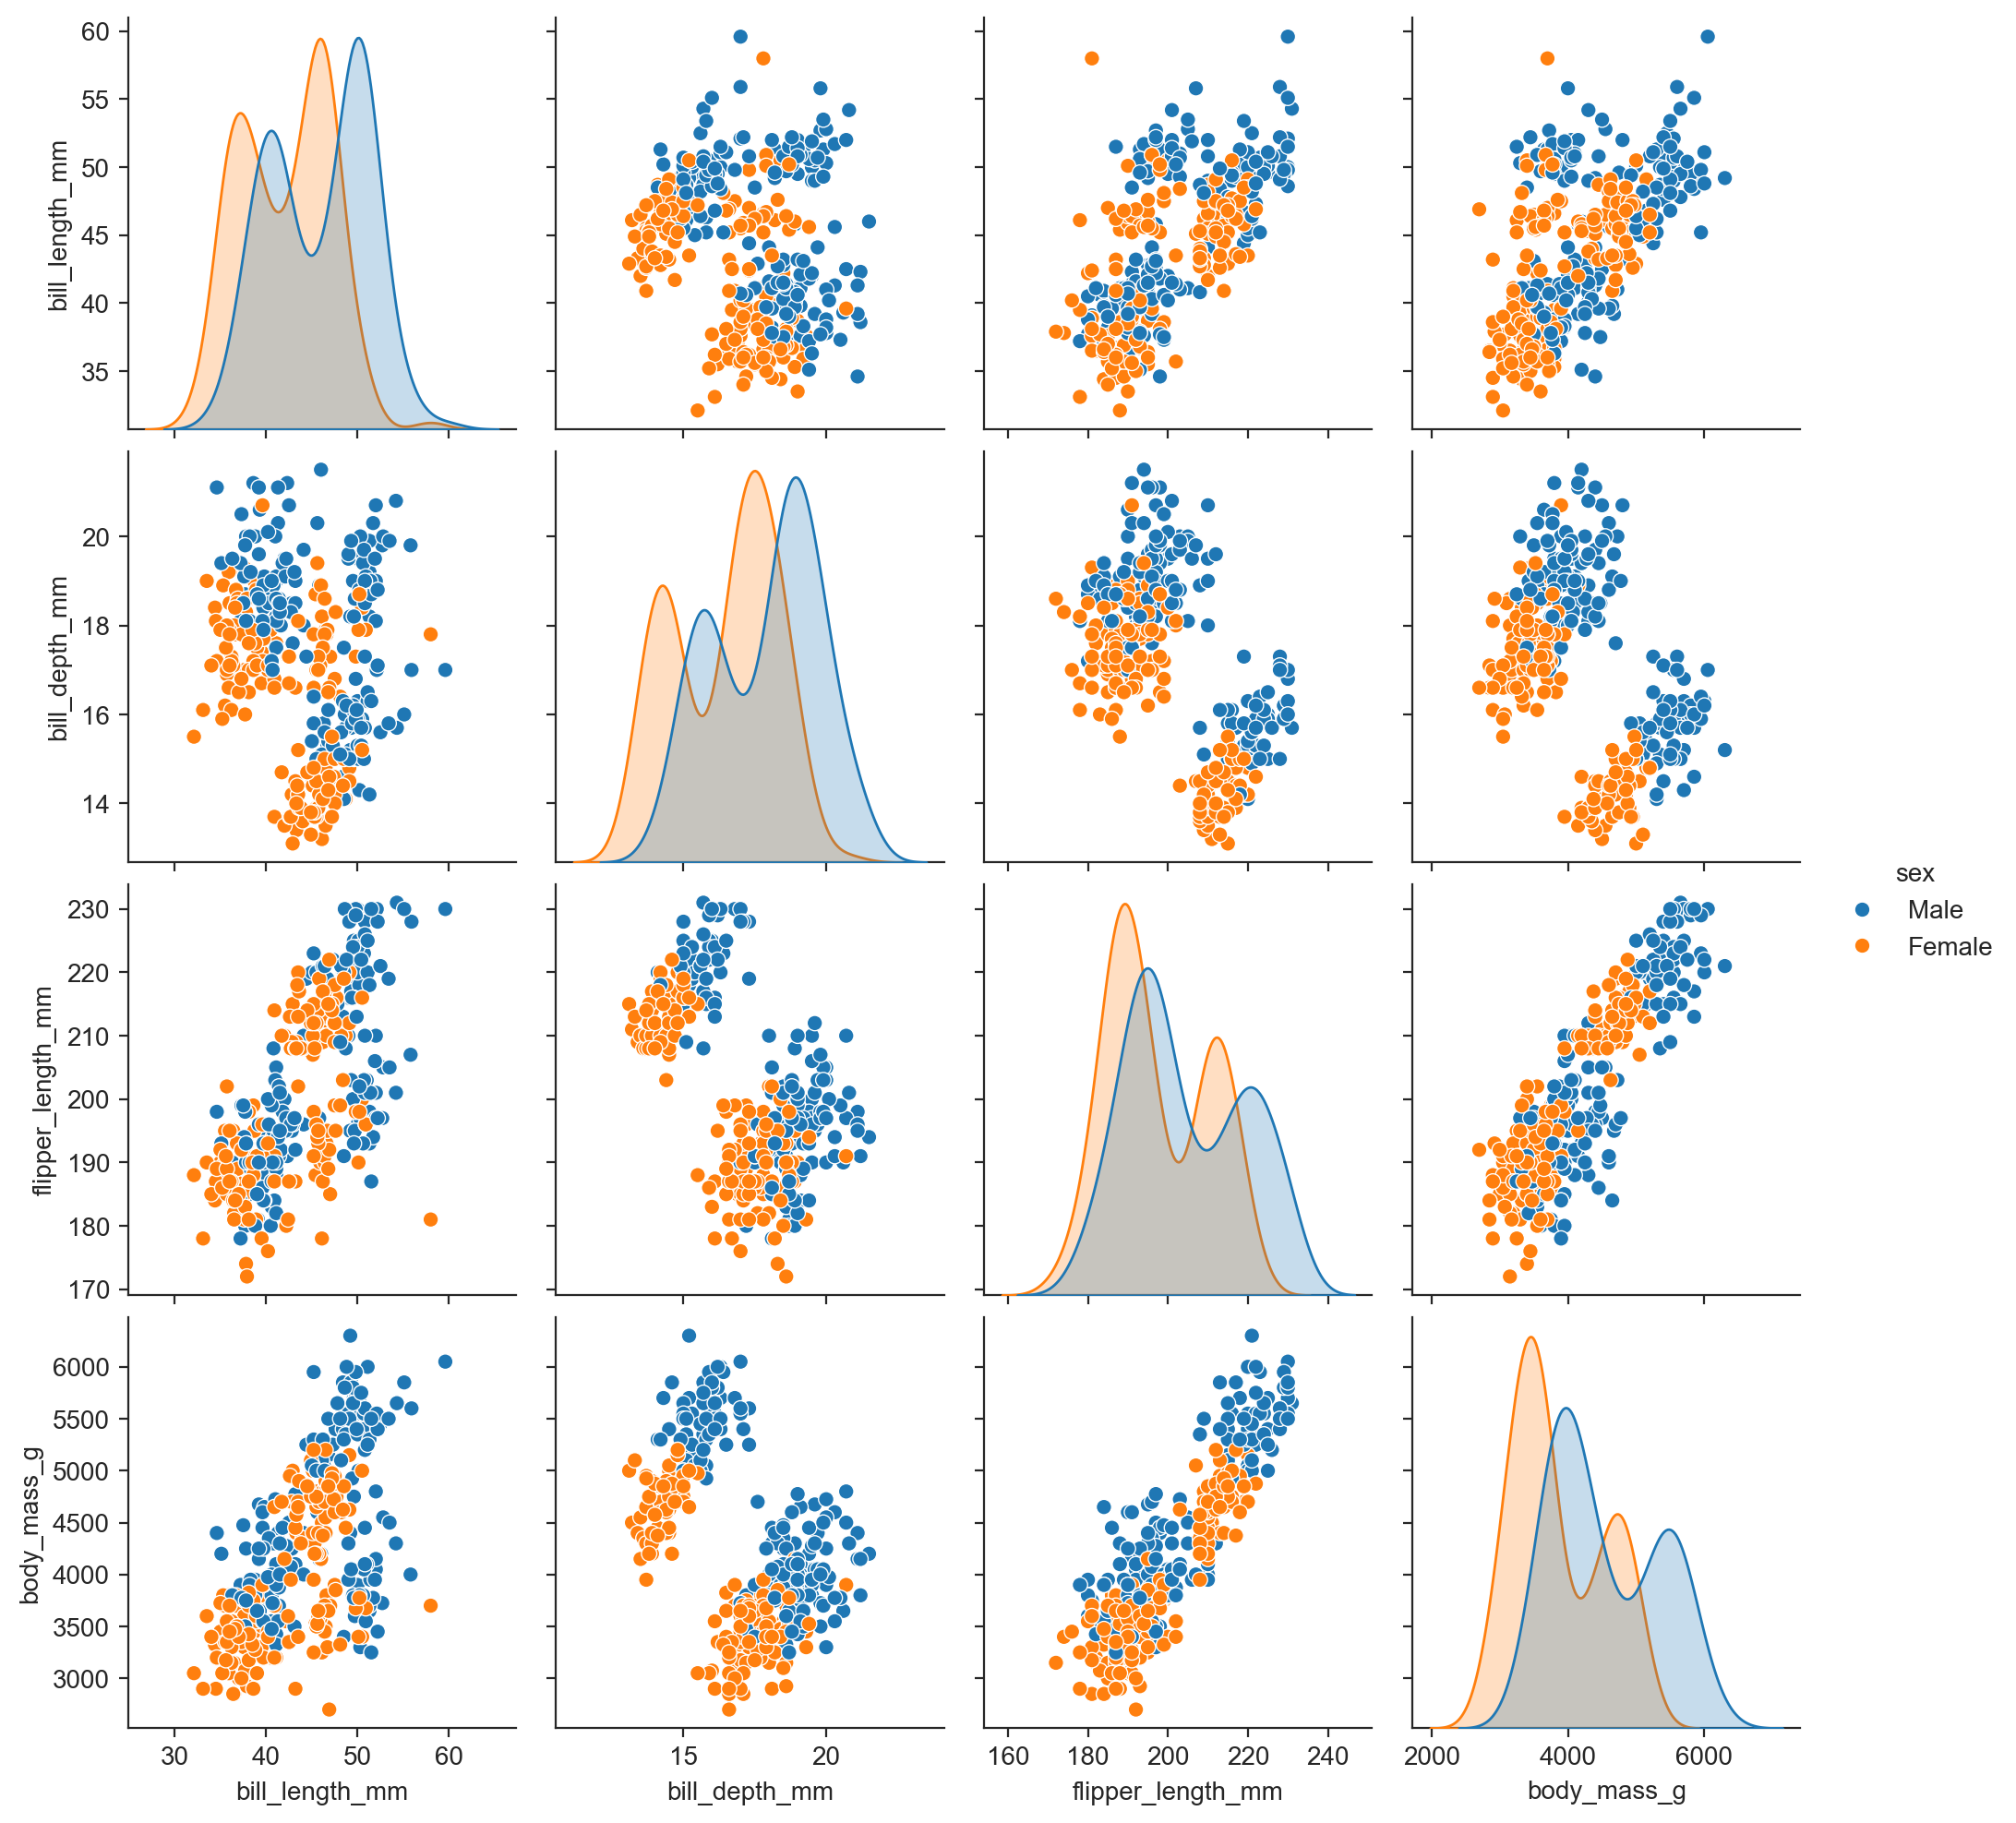

In [105]:
sns.pairplot(penguins, hue="sex") ;

## Exercises

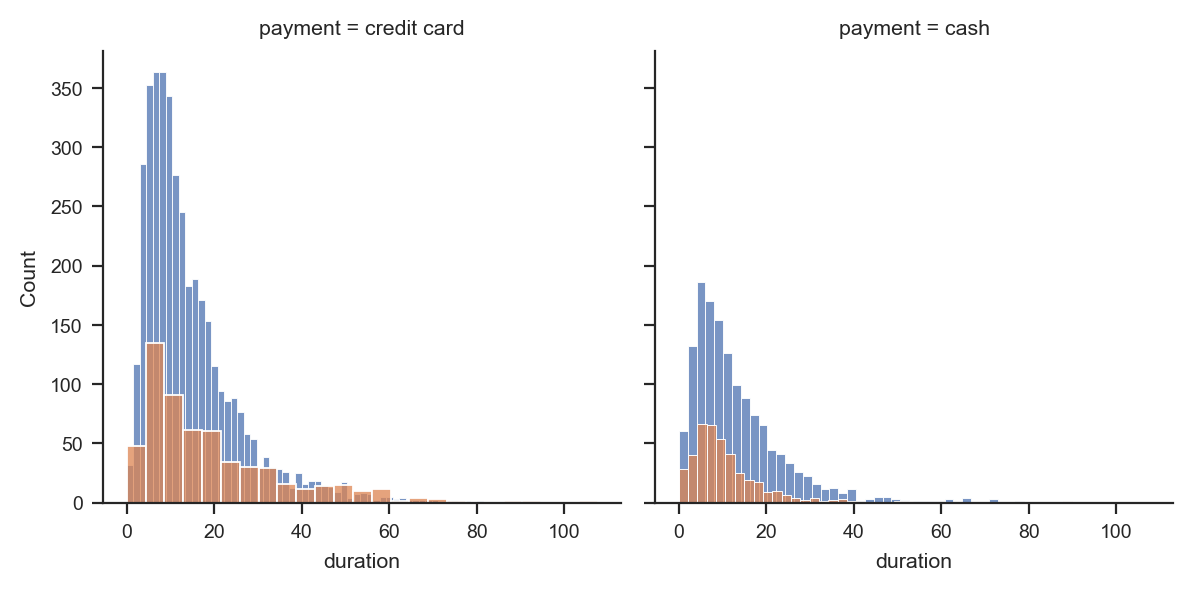

In [ ]:
g = sns.FacetGrid(rides, col="payment", hue="color") ;
g.map(sns.histplot, "duration") ;